In [4]:
import numpy as np

STUDENT = "Нарижна А.О."
VARIANT = 9
STUDENT_ID = 450 
SEED = 1000 * VARIANT + STUDENT_ID

rng = np.random.default_rng(SEED)

In [3]:
import textwrap

with open("source.txt", encoding="utf-8") as f:
    source = " ".join(f.read().split())

corpus = textwrap.wrap(
    source, width=65,
    break_long_words=False,
    break_on_hyphens=False
)

with open("corpus.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(corpus))

import os
import hashlib
import numpy as np
import pandas as pd
import cv2
from PIL import Image, ImageDraw, ImageFont

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

FONTS = ["C:/Windows/Fonts/arial.ttf"]

with open("corpus.txt", encoding="utf-8") as f:
    corpus = [s.strip() for s in f if 20 <= len(s.strip()) <= 70]

if len(corpus) < 40:
    raise ValueError("Потрібно щонайменше 40 рядків довжиною 20–70 символів у корпусі.")

lines = [str(s) for s in rng.choice(corpus, size=40, replace=False)]

def render_line(text, font_path, size=32, pad=12):
    font = ImageFont.truetype(font_path, size)
    l, t, r, b = font.getbbox(text)
    img = Image.new("L", (r - l + 2 * pad, b - t + 2 * pad), 255)
    ImageDraw.Draw(img).text((pad - l, pad - t), text, font=font, fill=0)
    return np.array(img)

def degrade(img, kind, level, rng):
    if kind == "font_height":
        # Масштабуємо текст без білих полів до заданої висоти.
        ys, xs = np.where(img < 255)
        text_img = img[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
        h, w = text_img.shape
        resized = cv2.resize(
            text_img,
            (max(1, round(w * level / h)), level),
            interpolation=cv2.INTER_AREA if level < h else cv2.INTER_CUBIC
        )
        return cv2.copyMakeBorder(resized, 12, 12, 12, 12,
                                  cv2.BORDER_CONSTANT, value=255)
    return img

FACTOR, LEVELS = "font_height", [40, 32, 24, 18, 14, 12, 10]
records = []

for i, text in enumerate(lines):
    font = FONTS[i % len(FONTS)]
    clean = render_line(text, font)

    for lvl in LEVELS:
        path = f"data/{i:03d}_{FACTOR}_{lvl}.png"
        cv2.imwrite(path, degrade(clean, FACTOR, lvl, rng))
        records.append({
            "id": i, "level": lvl, "path": path,
            "gt": text, "font": os.path.basename(font)
        })

ds = pd.DataFrame(records)
ds.to_csv("data/ground_truth.csv", index=False)

with open("data/ground_truth.csv", "rb") as f:
    sha = hashlib.sha256(f.read()).hexdigest()

print("Записів:", len(ds), "| SHA-256 еталону:", sha)

import matplotlib.pyplot as plt

fig, axes = plt.subplots(len(LEVELS), 1, figsize=(7, 0.75 * len(LEVELS)))

for ax, lvl in zip(axes, LEVELS):
    img = cv2.imread(f"data/000_{FACTOR}_{lvl}.png", cv2.IMREAD_GRAYSCALE)
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Висота = {lvl} px", fontsize=8, loc="left")
    ax.axis("off")

fig.suptitle(f"{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig("figures/fig0_samples.png", dpi=150, bbox_inches="tight")
plt.show()


NameError: name 'rng' is not defined

In [2]:
%pip install datasets

  Using cached datasets-5.1.0-py3-none-any.whl.metadata (24 kB)
  Using cached filelock-4.2.4-py3-none-any.whl.metadata (2.0 kB)
  Using cached pyarrow-26.0.0-cp314-cp314-win_amd64.whl.metadata (3.0 kB)
  Using cached dill-0.4.1-py3-none-any.whl.metadata (10 kB)
  Using cached xxhash-4.0.2-cp314-cp314-win_amd64.whl.metadata (18 kB)
  Using cached multiprocess-0.70.19-py314-none-any.whl.metadata (7.2 kB)
  Using cached fsspec-2026.7.0-py3-none-any.whl.metadata (10 kB)
  Using cached huggingface_hub-2.3.0-py3-none-any.whl.metadata (16 kB)
  Using cached aiohttp-3.14.5-cp314-cp314-win_amd64.whl.metadata (8.5 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached hf_xet-1.7.0-cp38-abi3-win_amd64.whl.metadata (4.9 kB)
  Using cached httpx2-2.16.0-py3-none-any.whl.metadata (10 kB)
  Using cached anyio-4.15.1-py3-none-any.whl.metadata (4.7 kB)
  Using cached httpcore2-2.16.0-py3-none-any.whl.metadata (27 kB)
  Using cached truststore-0.10.5-py3-none-any.whl.metadata 


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from datasets import load_dataset
import os
import pandas as pd

hf = load_dataset("Teklia/IAM-line", split="test")
print(hf)
print(hf.features)

os.makedirs("data/iam", exist_ok=True)
records_iam = []

for i in range(100):
    sample = hf[i]
    path = f"data/iam/{i:03d}.png"
    sample["image"].save(path)
    records_iam.append({
        "id": i,
        "dataset": "Teklia/IAM-line",
        "split": "test",
        "path": path,
        "gt": sample["text"]
    })

ds_iam = pd.DataFrame(records_iam)
ds_iam.to_csv("data/iam/ground_truth.csv", index=False)
print("Збережено рядків IAM:", len(ds_iam))
print("Еталон першого рядка:", ds_iam.loc[0, "gt"])


c:\Users\Аліна\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\Аліна\AppData\Local\Programs\Python\Python314\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Аліна\.cache\huggingface\hub\datasets--Teklia--IAM-line. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an admini

Dataset({
    features: ['image', 'text'],
    num_rows: 2915
})
{'image': Image(mode=None, decode=True), 'text': Value('string')}
Збережено рядків IAM: 100
Еталон першого рядка: assuredness " Bella Bella Marie " ( Parlophone ) , a lively song that changes tempo mid-way .


## Пункт 8. Гіпотези до запуску розпізнавання

Дата формулювання: 08.11.2026. Варіант 9, SEED = 9450.

Наведені значення є прогнозами, а не результатами вимірювань. Для перевірки використовуватиметься середній CER по зразках з однаковими правилами нормалізації тексту. Для синтетичного українського тексту Tesseract працюватиме з мовою ukr, для IAM та англомовних нотаток — eng.

1. **Вплив висоти тексту.** На синтетичному наборі без попередньої обробки Tesseract матиме середній CER не більше 10 % за висоти тексту 32 px, а за висоти 10 px — понад 10 %. Причина прогнозу: зменшення літер призводить до втрати дрібних елементів і злиття штрихів. Гіпотеза підтвердиться, якщо виконаються обидві нерівності.

2. **Вплив попередньої обробки.** На синтетичних рядках висотою 10 px послідовність із прикладу методички — збільшення у 2 рази, медіанний фільтр і бінаризація Оцу — зменшить середній CER Tesseract щонайменше на 5 відсоткових пунктів порівняно з тими самими рядками без обробки. Причина прогнозу: збільшення полегшить розпізнавання дрібних літер, а бінаризація виділить текст. Критерій: CER_raw − CER_prep ≥ 0,05.

3. **Власні фото проти синтетичних зображень.** Без попередньої обробки середній CER Tesseract на трьох власних фотографіях української рукописної сторінки буде щонайменше вдвічі вищим, ніж на синтетичних українських рядках висотою 32 px. Причина прогнозу: індивідуальний почерк, тіні та перспектива ускладнюють розпізнавання порівняно з друкованим текстом. Критерій: CER_фото ≥ 2 × CER_синтетика; обидва значення буде наведено окремо. Англомовні нотатки до цієї перевірки не включаються.

Після експериментів для кожної гіпотези буде наведено фактичні значення, оцінку «підтверджено» або «спростовано» та пояснення. Спростування гіпотези також є результатом експерименту.


## Пункт 9. Попередня обробка та абляційний експеримент
Функція preprocess — з підрозділу 4.3, абляція — за прикладом підрозділу 4.6. Порівнюємо ті самі 40 синтетичних рядків на висоті 10 px у п’яти конфігураціях Tesseract (ukr, --psm 7). Щоб виконати експеримент, використано функції OCR і CER з підрозділів 4.4–4.5; регістр і пунктуація зберігаються.


In [ ]:
%pip install pytesseract rapidfuzz


step
без обробки              0.053
+ збільшення             0.013
+ медіанний фільтр       0.016
+ бінаризація Оцу        0.032
адаптивна замість Оцу    0.025


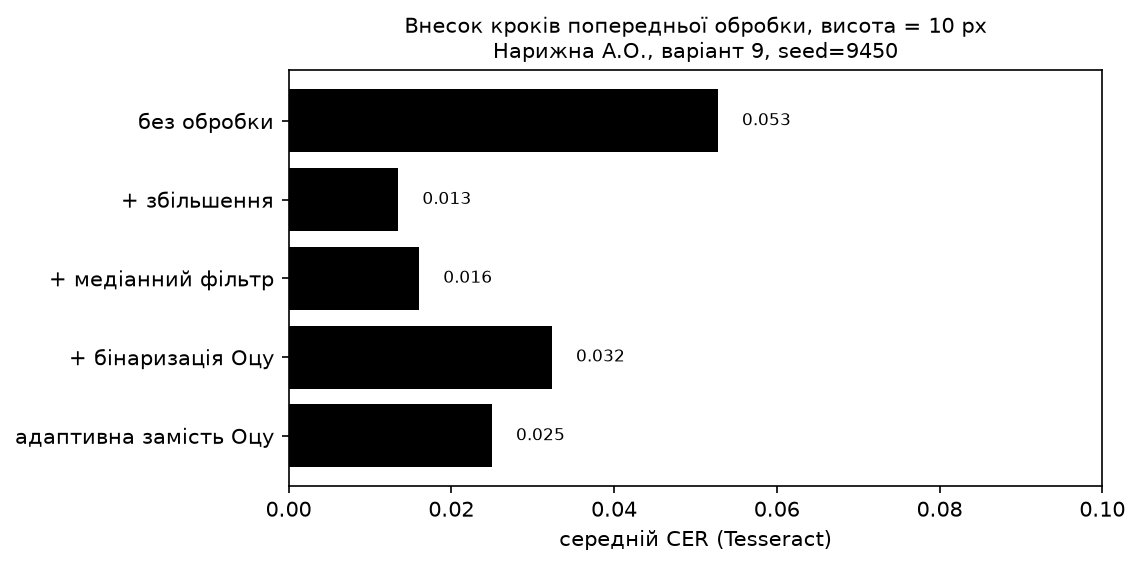

In [1]:
import os, re, time, unicodedata
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import pytesseract
from rapidfuzz.distance import Levenshtein

pytesseract.pytesseract.tesseract_cmd = r"D:\Tesseract-OCR\tesseract.exe"

def preprocess(img, steps=()):
    out = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    if "upscale" in steps:
        out = cv2.resize(out, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    if "denoise" in steps:
        out = cv2.medianBlur(out, 3)
    if "binarize" in steps:
        out = cv2.threshold(out, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
    if "adaptive" in steps:
        out = cv2.adaptiveThreshold(out, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv2.THRESH_BINARY, 31, 15)
    return out

# Нормалізація, CER та OCR — з підрозділів 4.4–4.5 методички.
APOSTROPHES = "\u2019\u02bc\u2018\u0060\u00b4"

def normalize(s):
    s = unicodedata.normalize("NFC", str(s))
    for a in APOSTROPHES:
        s = s.replace(a, "'")
    return re.sub(r"\s+", " ", s).strip()

def cer(gt, pred):
    gt, pred = normalize(gt), normalize(pred)
    return Levenshtein.distance(gt, pred) / max(1, len(gt))

def ocr_tesseract(img, lang="ukr", psm=7):
    t0 = time.perf_counter()
    d = pytesseract.image_to_data(img, lang=lang, config=f"--oem 1 --psm {psm}",
                                  output_type=pytesseract.Output.DICT)
    words = [(w, float(c)) for w, c in zip(d["text"], d["conf"])
             if w.strip() and float(c) >= 0]
    text = " ".join(w for w, _ in words)
    conf = np.mean([c for _, c in words]) / 100 if words else 0.0
    return text, conf, time.perf_counter() - t0

def stamp(ax, title):
    ax.set_title(f"{title}\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)

LVL = 10
ablation = {"без обробки": (), "+ збільшення": ("upscale",),
            "+ медіанний фільтр": ("upscale", "denoise"),
            "+ бінаризація Оцу": ("upscale", "denoise", "binarize"),
            "адаптивна замість Оцу": ("upscale", "denoise", "adaptive")}
ds = pd.read_csv("data/ground_truth.csv")
abl_rows = []
for r in ds[ds.level == LVL].itertuples():
    img = cv2.imread(r.path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(r.path)
    for name, steps in ablation.items():
        text, conf, sec = ocr_tesseract(preprocess(img, steps))
        abl_rows.append({"id": r.id, "level": LVL, "step": name,
                         "gt": r.gt, "pred": text, "conf": conf,
                         "sec": sec, "cer": cer(r.gt, text)})
abl_results = pd.DataFrame(abl_rows)
abl_results.to_csv("ablation_results.csv", index=False)
abl = abl_results.groupby("step", sort=False)["cer"].mean()
abl.to_csv("ablation_summary.csv", header=["CER_mean"])
os.makedirs("figures", exist_ok=True)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(abl.index[::-1], abl.values[::-1], color="black")
for y, v in enumerate(abl.values[::-1]):
    ax.text(v + 0.003, y, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlim(0, max(0.1, abl.max() * 1.2))
ax.set_xlabel("середній CER (Tesseract)")
stamp(ax, f"Внесок кроків попередньої обробки, висота = {LVL} px")
fig.savefig("figures/fig5_ablation.png", dpi=150, bbox_inches="tight")
print(abl.round(3))
plt.show()


## Пункт 10. Розпізнавання трьох груп даних
Обидва інструменти завершили по 384 зразки: 280 синтетичних, 100 IAM та чотири власні фото. Лише raw. Блоки Tesseract та Ollama незалежні. VLM для неперсональних даних запускалася у Colab з T4; власні фото — локально на CPU з num_ctx=8192. Три ранні синтетичні відповіді VLM збережено з локального тесту.
Не виконуйте всі комірки пункту 10 автоматично: блок Colab запускається тільки у Colab, решта — локально. Готові відповіді пропускаються.


### 10.1 Tesseract локально
Дві комірки нижче: синтетичні дані та IAM, потім чотири власні фото. Шлях до tesseract.exe відповідає цьому ПК.


In [ ]:
%pip install pandas Pillow pytesseract pillow-heif


In [ ]:
import time
from pathlib import Path
import pandas as pd
import pytesseract
from PIL import Image

pytesseract.pytesseract.tesseract_cmd = r"D:\Tesseract-OCR\tesseract.exe"
RESULTS = Path("recognition_results.csv")
KEY = ["group", "id", "level", "engine", "prep"]
synthetic = pd.read_csv("data/ground_truth.csv", dtype={"id": str}, keep_default_na=False)
synthetic["group"], synthetic["lang"] = "synthetic", "ukr"
iam = pd.read_csv("data/iam/ground_truth.csv", dtype={"id": str}, keep_default_na=False)
iam["group"], iam["lang"], iam["level"] = "iam", "eng", -1
columns = ["group", "id", "level", "path", "gt", "lang"]
data = pd.concat([synthetic[columns], iam[columns]], ignore_index=True)
rows = (pd.read_csv(RESULTS, dtype={"id": str}, keep_default_na=False).to_dict("records")
        if RESULTS.exists() else [])
completed = {(r["group"], str(r["id"]), int(r["level"])) for r in rows
             if r["engine"] == "Tesseract" and r["prep"] == "raw"}

# За прикладом підрозділу 4.4; для рядків --psm 7.
for r in data.itertuples(index=False):
    key = (r.group, str(r.id), int(r.level))
    if key in completed:
        continue
    with Image.open(r.path) as source:
        image = source.convert("L")
    t0 = time.perf_counter()
    output = pytesseract.image_to_data(image, lang=r.lang,
              config="--oem 1 --psm 7", output_type=pytesseract.Output.DICT)
    words = [(w, float(c)) for w, c in zip(output["text"], output["conf"])
             if w.strip() and float(c) >= 0]
    pred = " ".join(w for w, _ in words)
    conf = sum(c for _, c in words) / len(words) / 100 if words else 0.0
    rows.append({"group": r.group, "id": str(r.id), "level": int(r.level),
                 "engine": "Tesseract", "model": "Tesseract", "prep": "raw",
                 "gt": r.gt, "pred": pred, "conf": conf,
                 "sec": time.perf_counter() - t0, "lang": r.lang, "psm": 7})
    temporary = RESULTS.with_suffix(".tmp.csv")
    pd.DataFrame(rows).to_csv(temporary, index=False)
    temporary.replace(RESULTS)
    completed.add(key)
print("Tesseract: синтетичні дані та IAM завершено")


In [1]:
import time
from pathlib import Path

import pandas as pd
import pytesseract
import pillow_heif
from PIL import Image, ImageOps

pillow_heif.register_heif_opener()

pytesseract.pytesseract.tesseract_cmd = (
    r"D:\Tesseract-OCR\tesseract.exe"
)

RESULTS = Path("recognition_results.csv")
KEY = ["group", "id", "level", "engine", "prep"]

# Зберігаємо всі наявні відповіді.
results = pd.read_csv(
    RESULTS,
    dtype={"id": str},
    keep_default_na=False,
)
rows = results.to_dict("records")

completed = {
    str(row["id"])
    for row in rows
    if row["engine"] == "Tesseract"
    and row["group"] == "own"
    and row["prep"] == "raw"
}

photos = sorted(
    p for p in Path("my_photos").iterdir()
    if p.suffix.lower() == ".heic"
)
assert len(photos) == 4, "Очікуються чотири власні HEIC-фото."

for photo in photos:
    if photo.stem in completed:
        continue

    gt = photo.with_suffix(".txt").read_text(
        encoding="utf-8-sig"
    ).strip()

    lang = "eng" if photo.stem == "IMG_1405" else "ukr"

    with Image.open(photo) as source:
        image = ImageOps.exif_transpose(source).convert("L")

    print(photo.name, "— розпізнавання…", flush=True)
    started = time.perf_counter()

    # За прикладом методички; psm 6 — блок тексту на сторінці.
    output = pytesseract.image_to_data(
        image,
        lang=lang,
        config="--oem 1 --psm 6",
        output_type=pytesseract.Output.DICT,
    )

    words = [
        (word, float(conf))
        for word, conf in zip(output["text"], output["conf"])
        if word.strip() and float(conf) >= 0
    ]

    pred = " ".join(word for word, _ in words)
    confidence = (
        sum(conf for _, conf in words) / len(words) / 100
        if words else 0.0
    )
    seconds = time.perf_counter() - started

    rows.append({
        "group": "own",
        "id": photo.stem,
        "level": -1,
        "engine": "Tesseract",
        "model": "Tesseract",
        "prep": "raw",
        "gt": gt,
        "pred": pred,
        "conf": confidence,
        "sec": seconds,
        "lang": lang,
        "psm": 6,
    })

    temporary = RESULTS.with_suffix(".tmp.csv")
    pd.DataFrame(rows).to_csv(temporary, index=False)
    temporary.replace(RESULTS)

    completed.add(photo.stem)
    print(f"Збережено, {seconds:.1f} с", flush=True)

res = pd.DataFrame(rows)

assert not res.duplicated(KEY).any()

print("\nКількість відповідей:")
print(res.groupby(["engine", "group"]).size())

IMG_1402.heic — розпізнавання…
Збережено, 2.3 с
IMG_1403.heic — розпізнавання…
Збережено, 1.4 с
IMG_1404.heic — розпізнавання…
Збережено, 2.5 с
IMG_1405.heic — розпізнавання…
Збережено, 2.5 с

Кількість відповідей:
engine     group    
Tesseract  iam          100
           own            4
           synthetic    280
VLM        iam          100
           own            4
           synthetic    280
dtype: int64


### Пункт 10 — VLM у Colab
Цей блок запускається лише у Colab після встановлення Ollama, завантаження qwen2.5vl:3b та розпакування lab3_colab_data.zip у /content. Потрібні пакети ollama і pandas. Власні фото не завантажуються. Готовий recognition_results.csv завантажте та перенесіть у локальний проєкт під назвою recognition_results_colab.csv, не замінюючи локальний файл.


In [ ]:
%pip install ollama pandas


In [ ]:
import os
os.chdir("/content")
from pathlib import Path
import time
import ollama
import pandas as pd

MODEL = "qwen2.5vl:3b"
RESULTS = Path("recognition_results.csv")
PROMPT = ("Перепиши дослівно весь текст із зображення, зберігаючи рядки. "
          "Нічого не виправляй, не перекладай і не додавай пояснень.")
KEY = ["group", "id", "level", "engine", "model", "prep"]

def read_results(path):
    if path.exists():
        return pd.read_csv(path, dtype={"id": str}, keep_default_na=False).to_dict("records")
    return []

def recognize_vlm(data, rows):
    completed = {(r["group"], str(r["id"]), int(r["level"])) for r in rows
                 if r["engine"] == "VLM" and r["model"] == MODEL and r["prep"] == "raw"}
    for r in data.itertuples(index=False):
        key = (r.group, str(r.id), int(r.level))
        if key in completed:
            continue
        if not Path(r.path).is_file():
            raise FileNotFoundError(r.path)
        print(r.group, r.id, r.level, "— розпізнавання…", flush=True)
        t0 = time.perf_counter()
        response = ollama.chat(model=MODEL, options=OPTIONS,
                              messages=[{"role": "user", "content": PROMPT,
                                         "images": [str(r.path)]}])
        seconds = time.perf_counter() - t0
        rows.append({"group": r.group, "id": str(r.id), "level": int(r.level),
                     "engine": "VLM", "model": MODEL, "prep": "raw", "gt": r.gt,
                     "pred": response["message"]["content"], "conf": None, "sec": seconds,
                     "lang": r.lang, "psm": r.psm})
        temporary = RESULTS.with_suffix(".tmp.csv")
        pd.DataFrame(rows).to_csv(temporary, index=False)
        temporary.replace(RESULTS)
        completed.add(key)
        print(f"Збережено, {seconds:.1f} с", flush=True)
    return pd.DataFrame(rows)

# У Colab GPU не вимикаємо.
OPTIONS = {"temperature": 0}
synthetic = pd.read_csv("data/ground_truth.csv", dtype={"id": str}, keep_default_na=False)
synthetic["group"], synthetic["lang"], synthetic["psm"] = "synthetic", "ukr", 7
iam = pd.read_csv("data/iam/ground_truth.csv", dtype={"id": str}, keep_default_na=False)
iam["group"], iam["lang"], iam["psm"], iam["level"] = "iam", "eng", 7, -1
columns = ["group", "id", "level", "path", "gt", "lang", "psm"]
data = pd.concat([synthetic[columns], iam[columns]], ignore_index=True)
assert data.groupby("group").size().to_dict() == {"synthetic": 280, "iam": 100}
results = recognize_vlm(data, read_results(RESULTS))
vlm = results[(results.engine == "VLM") & (results.model == MODEL)
              & (results.prep == "raw") & results.group.isin(["synthetic", "iam"])]
assert vlm.groupby("group").size().to_dict() == {"synthetic": 280, "iam": 100}
assert not vlm.duplicated(["group", "id", "level"]).any()
print("Colab завершено: 380 відповідей VLM")
from google.colab import files
files.download(str(RESULTS))


### Пункт 10 — VLM для власних фото локально
Цей блок запускається на ПК з папки проєкту. Потрібна відкрита Ollama з моделлю qwen2.5vl:3b. Встановлення: %pip install ollama pandas Pillow pillow-heif. Блок спочатку імпортує відповіді VLM із recognition_results_colab.csv, якщо він є, та зберігає локальні відповіді Tesseract. Потім розпізнає лише чотири власні фото. num_gpu=0 обходить виявлений збій CUDA на робочому ПК. Власні фото не надсилаються в Colab.


In [ ]:
%pip install ollama pandas Pillow pillow-heif


In [2]:
from pathlib import Path
import time
import ollama
import pandas as pd

MODEL = "qwen2.5vl:3b"
RESULTS = Path("recognition_results.csv")
PROMPT = ("Перепиши дослівно весь текст із зображення, зберігаючи рядки. "
          "Нічого не виправляй, не перекладай і не додавай пояснень.")
KEY = ["group", "id", "level", "engine", "model", "prep"]

def read_results(path):
    if path.exists():
        return pd.read_csv(path, dtype={"id": str}, keep_default_na=False).to_dict("records")
    return []

def recognize_vlm(data, rows):
    completed = {(r["group"], str(r["id"]), int(r["level"])) for r in rows
                 if r["engine"] == "VLM" and r["model"] == MODEL and r["prep"] == "raw"}
    for r in data.itertuples(index=False):
        key = (r.group, str(r.id), int(r.level))
        if key in completed:
            continue
        if not Path(r.path).is_file():
            raise FileNotFoundError(r.path)
        print(r.group, r.id, r.level, "— розпізнавання…", flush=True)
        t0 = time.perf_counter()
        response = ollama.chat(model=MODEL, options=OPTIONS,
                              messages=[{"role": "user", "content": PROMPT,
                                         "images": [str(r.path)]}])
        seconds = time.perf_counter() - t0
        rows.append({"group": r.group, "id": str(r.id), "level": int(r.level),
                     "engine": "VLM", "model": MODEL, "prep": "raw", "gt": r.gt,
                     "pred": response["message"]["content"], "conf": None, "sec": seconds,
                     "lang": r.lang, "psm": r.psm})
        temporary = RESULTS.with_suffix(".tmp.csv")
        pd.DataFrame(rows).to_csv(temporary, index=False)
        temporary.replace(RESULTS)
        completed.add(key)
        print(f"Збережено, {seconds:.1f} с", flush=True)
    return pd.DataFrame(rows)

from PIL import Image, ImageOps
import pillow_heif
pillow_heif.register_heif_opener()
# На ПК зі збоєм CUDA вимикаємо GPU лише для цього виклику.
OPTIONS = {
    "temperature": 0,
    "num_gpu": 0,
    "num_ctx": 8192,
}

# CSV із Colab покладіть поруч із ноутбуком під цією окремою назвою.
# Наявний локальний recognition_results.csv з відповідями Tesseract не замінюйте.
rows = read_results(RESULTS)
cloud = Path("recognition_results_colab.csv")
if cloud.exists():
    imported = [r for r in read_results(cloud) if r["engine"] == "VLM"
                and r["model"] == MODEL and r["prep"] == "raw"
                and r["group"] in ["synthetic", "iam"]]
    merged = pd.DataFrame(rows + imported).drop_duplicates(KEY, keep="last")
    rows = merged.to_dict("records")
    temporary = RESULTS.with_suffix(".tmp.csv")
    merged.to_csv(temporary, index=False)
    temporary.replace(RESULTS)

Path("data/my_photos").mkdir(parents=True, exist_ok=True)
own_rows = []
for photo in sorted(Path("my_photos").iterdir()):
    if photo.suffix.lower() != ".heic":
        continue
    gt = photo.with_suffix(".txt").read_text(encoding="utf-8-sig").strip()
    png = Path("data/my_photos") / (photo.stem + ".png")
    with Image.open(photo) as image:
        ImageOps.exif_transpose(image).convert("RGB").save(png)
    own_rows.append({"group": "own", "id": photo.stem, "level": -1,
                     "path": png.as_posix(), "gt": gt,
                     "lang": "eng" if photo.stem == "IMG_1405" else "ukr", "psm": 6})
data = pd.DataFrame(own_rows)
assert len(data) == 4, "Очікуються чотири HEIC-фото з однойменними TXT"
results = recognize_vlm(data, rows)
vlm = results[(results.engine == "VLM") & (results.model == MODEL)
              & (results.prep == "raw") & (results.group == "own")]
assert len(vlm) == 4
assert not vlm.duplicated(["group", "id", "level"]).any()
print("Власні фото завершено: 4 відповіді VLM")


own IMG_1404 -1 — розпізнавання…
Збережено, 433.6 с
own IMG_1405 -1 — розпізнавання…
Збережено, 390.8 с
Власні фото завершено: 4 відповіді VLM


### Перевірка пункту 10
Запускати локально після завершення Colab, імпорту CSV та розпізнавання власних фото.


In [1]:
import pandas as pd
res = pd.read_csv("recognition_results.csv", dtype={"id": str}, keep_default_na=False)
print(res.groupby(["engine", "group"]).size())
expected = {("Tesseract", "synthetic"): 280, ("Tesseract", "iam"): 100, ("Tesseract", "own"): 4, ("VLM", "synthetic"): 280, ("VLM", "iam"): 100, ("VLM", "own"): 4}
assert res.groupby(["engine", "group"]).size().to_dict() == expected
assert not res.duplicated(["group", "id", "level", "engine", "prep"]).any()
assert set(res["prep"]) == {"raw"}
assert set(res.loc[res.engine == "VLM", "model"]) == {"qwen2.5vl:3b"}


engine     group    
Tesseract  iam          100
           own            4
           synthetic    280
VLM        iam          100
           own            4
           synthetic    280
Перевірку пройдено: 768 відповідей.


## Пункт 11. CER WER та нормалізація тексту
Функції normalize, cer та wer — за прикладом підрозділу 4.5 методички. NFC, уніфікація апострофів, згортання пробільних символів та видалення крайових пробілів виконуються однаково для еталону й відповіді. Регістр і пунктуація зберігаються як частина точного розпізнавання.
CER — відстань Левенштейна по символах / кількість символів еталону; WER — по словах / кількість слів еталону. Усереднення макро: однакова вага кожного зразка. Значення подано частками, 0.05 = 5 %. Вставлення можуть спричинити значення понад 1.
results.csv містить 768 відповідей із cer та wer; results_summary.csv — підсумок за інструментом, групою, конфігурацією і рівнем висоти. sec_mean зберігається з пункту 10; для VLM він залежить від локального або хмарного запуску.


In [ ]:
%pip install rapidfuzz


In [1]:
import re
import unicodedata
import pandas as pd
from rapidfuzz.distance import Levenshtein

res = pd.read_csv("recognition_results.csv", dtype={"id": str}, keep_default_na=False)
APOSTROPHES = "\u2019\u02bc\u2018\u0060\u00b4"

def normalize(s):
    s = unicodedata.normalize("NFC", str(s))
    for a in APOSTROPHES:
        s = s.replace(a, "'")
    return re.sub(r"\s+", " ", s).strip()

def cer(gt, pred):
    gt, pred = normalize(gt), normalize(pred)
    return Levenshtein.distance(gt, pred) / max(1, len(gt))

def wer(gt, pred):
    gt, pred = normalize(gt).split(), normalize(pred).split()
    return Levenshtein.distance(gt, pred) / max(1, len(gt))

res["cer"] = [cer(g, p) for g, p in zip(res["gt"], res["pred"])]
res["wer"] = [wer(g, p) for g, p in zip(res["gt"], res["pred"])]
res.to_csv("results.csv", index=False)

summary = (res.groupby(["engine", "group", "prep", "level"])
              .agg(CER_mean=("cer", "mean"), CER_median=("cer", "median"),
                   WER_mean=("wer", "mean"), sec_mean=("sec", "mean")))
summary.to_csv("results_summary.csv")
print(summary.round(4))


                                CER_mean  CER_median  WER_mean  sec_mean
engine    group     prep level                                          
Tesseract iam       raw  -1       0.4896      0.4741    0.8928    0.2035
          own       raw  -1       0.7893      0.7888    1.1111    2.1672
          synthetic raw   10      0.0527      0.0325    0.2043    0.0981
                          12      0.0233      0.0077    0.0870    0.1098
                          14      0.0151      0.0000    0.0408    0.1133
                          18      0.0147      0.0000    0.0405    0.1193
                          24      0.0127      0.0000    0.0330    0.1226
                          32      0.0168      0.0000    0.0391    0.1266
                          40      0.0131      0.0000    0.0350    0.1358
VLM       iam       raw  -1       0.0974      0.0556    0.3397    1.9484
          own       raw  -1       0.5518      0.5362    0.7642  413.9018
          synthetic raw   10      0.0440      0.000

## Пункт 12. Обов’язкові графіки
Сім рисунків за переліком пункту 12. Код спирається на приклади підрозділів 4.6–4.7. Бутстреп: 2000 перевибірок, 95 % інтервали, SEED = 9450.
Для VLM графік впевненості не будується, бо вона не повертає confidence. Для порівняння груп синтетичні зображення згруповано за початковим id рядка при бутстрепі; для чотирьох залежних власних фото ДІ не оцінюються.
На діаграмі часу CPU та Colab T4 позначено окремо; три локальні проби VLM виключено з панелі хмарної синтетики, разом із відповідними зразками Tesseract. Це не порівняння алгоритмів на однаковому обладнанні.


In [ ]:
%pip install matplotlib scipy rapidfuzz


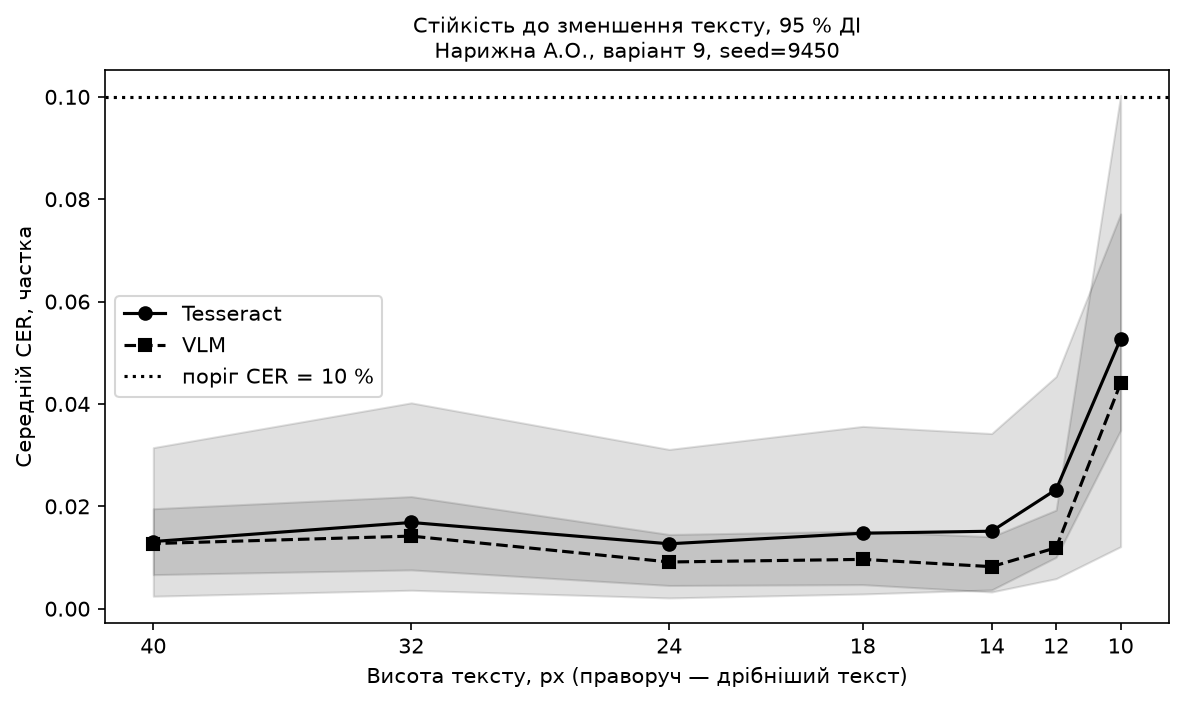

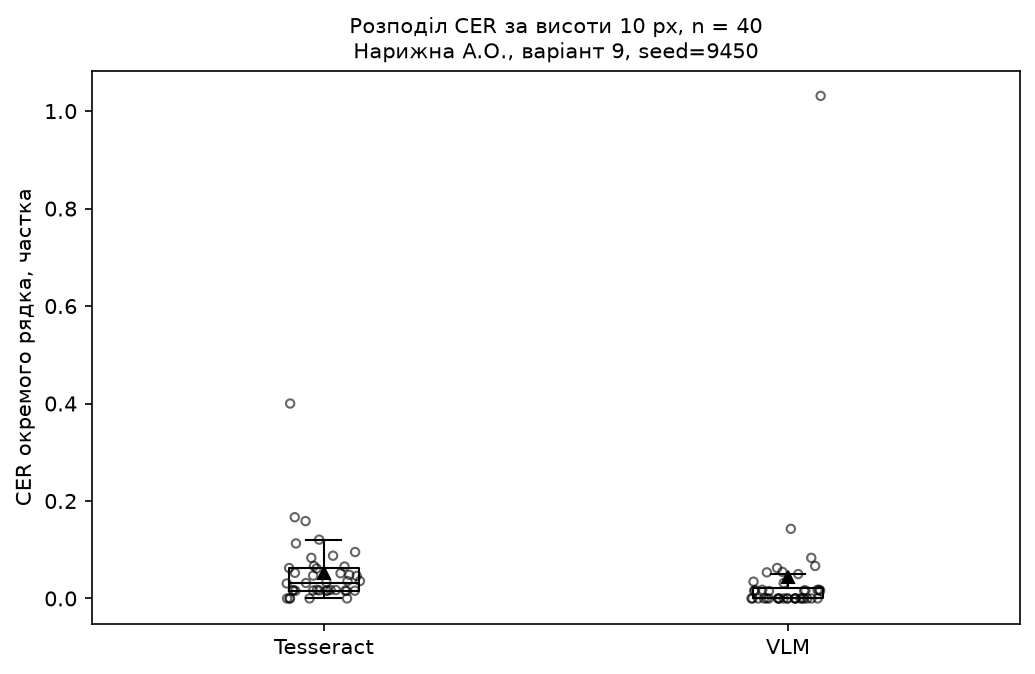

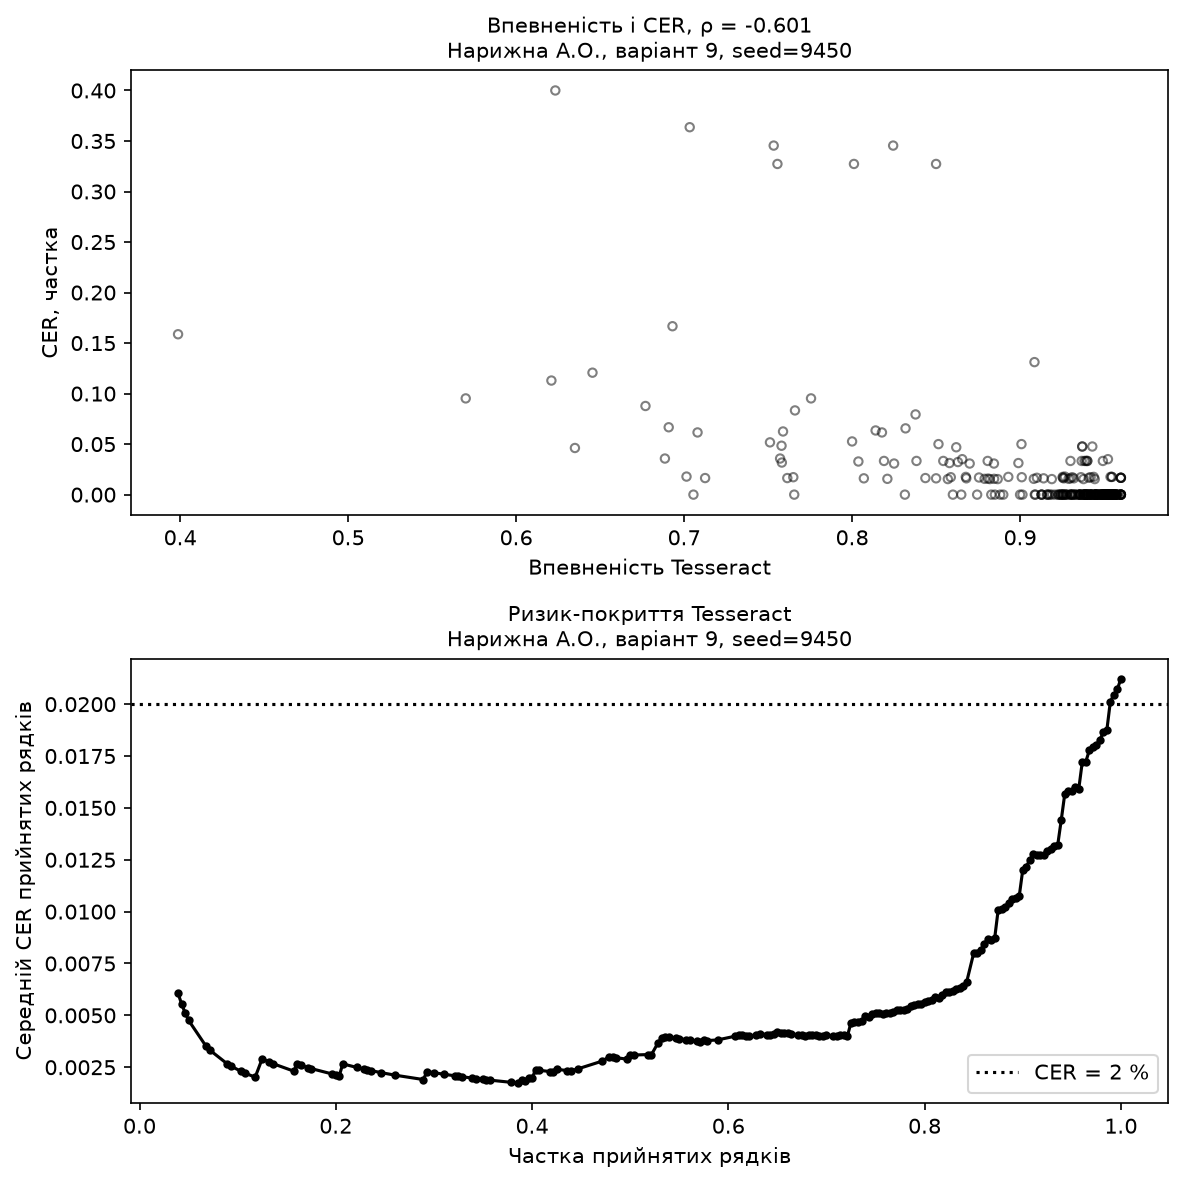

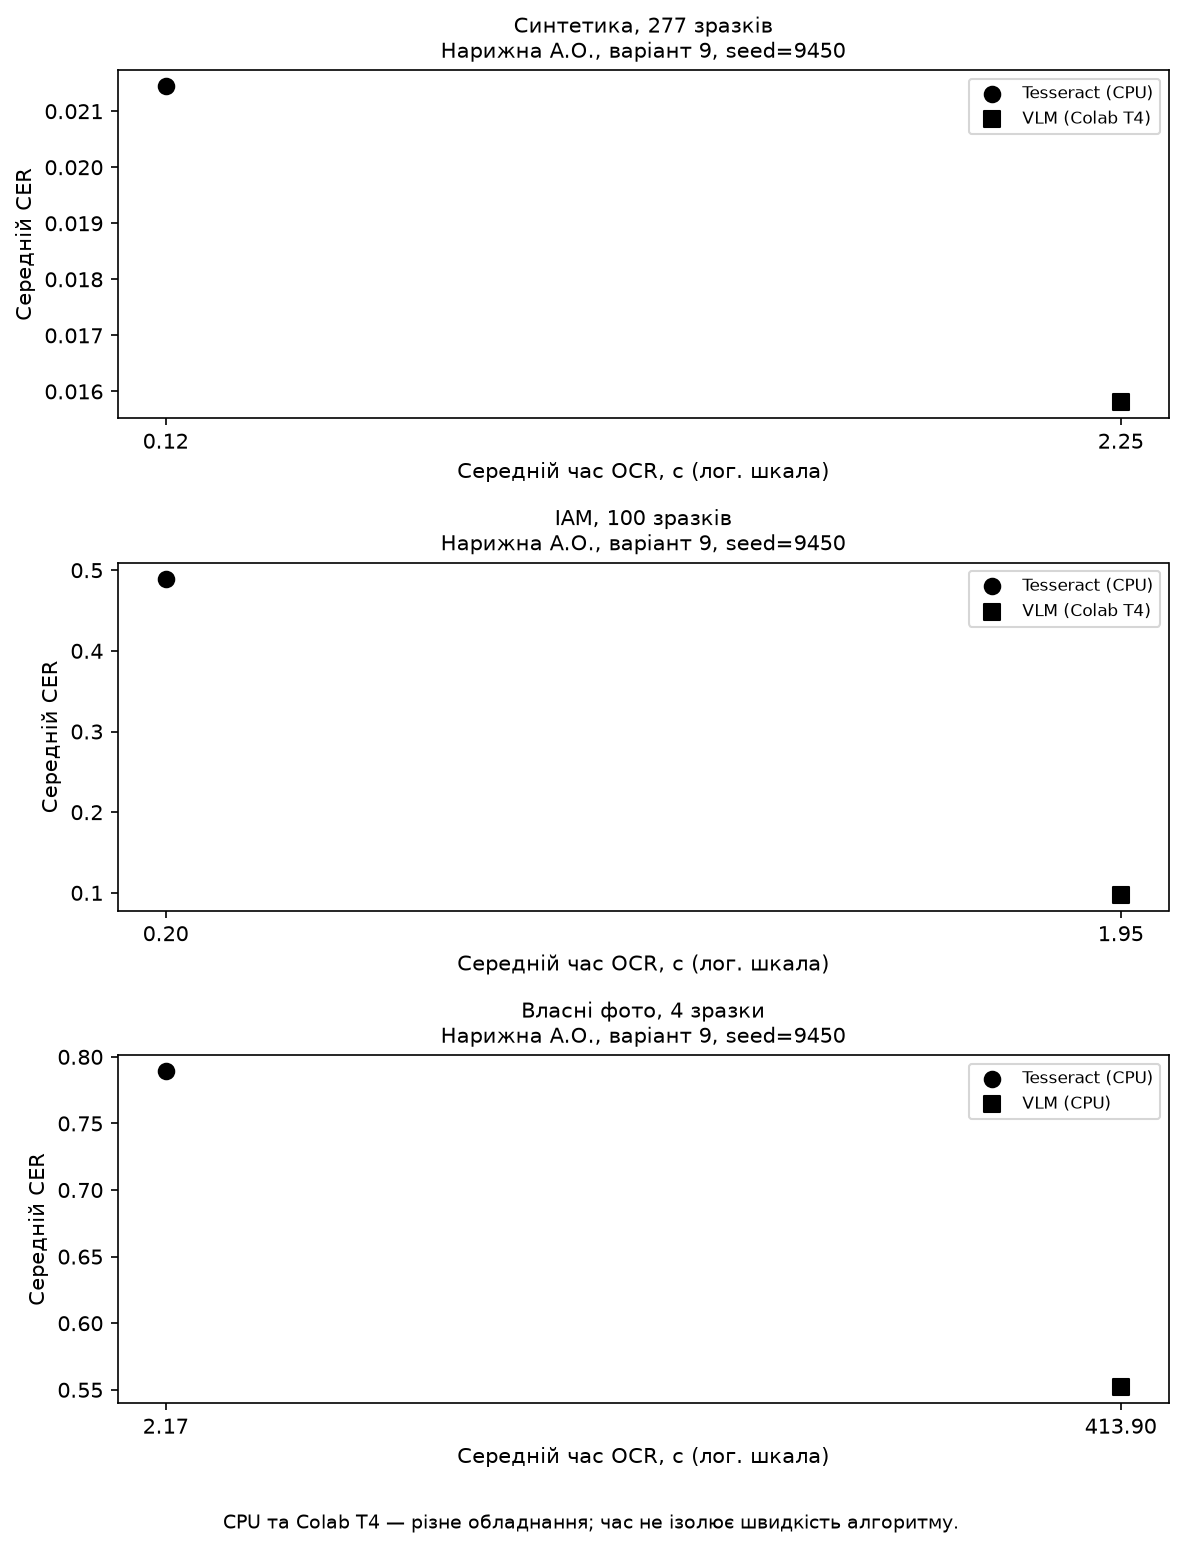

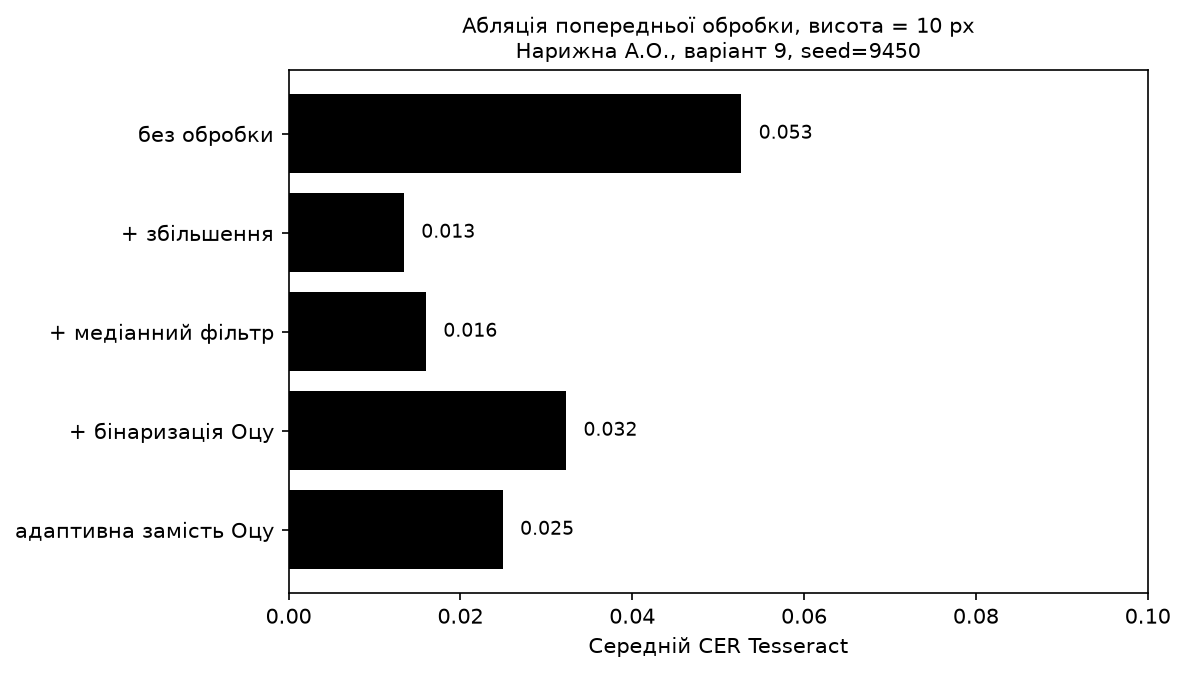

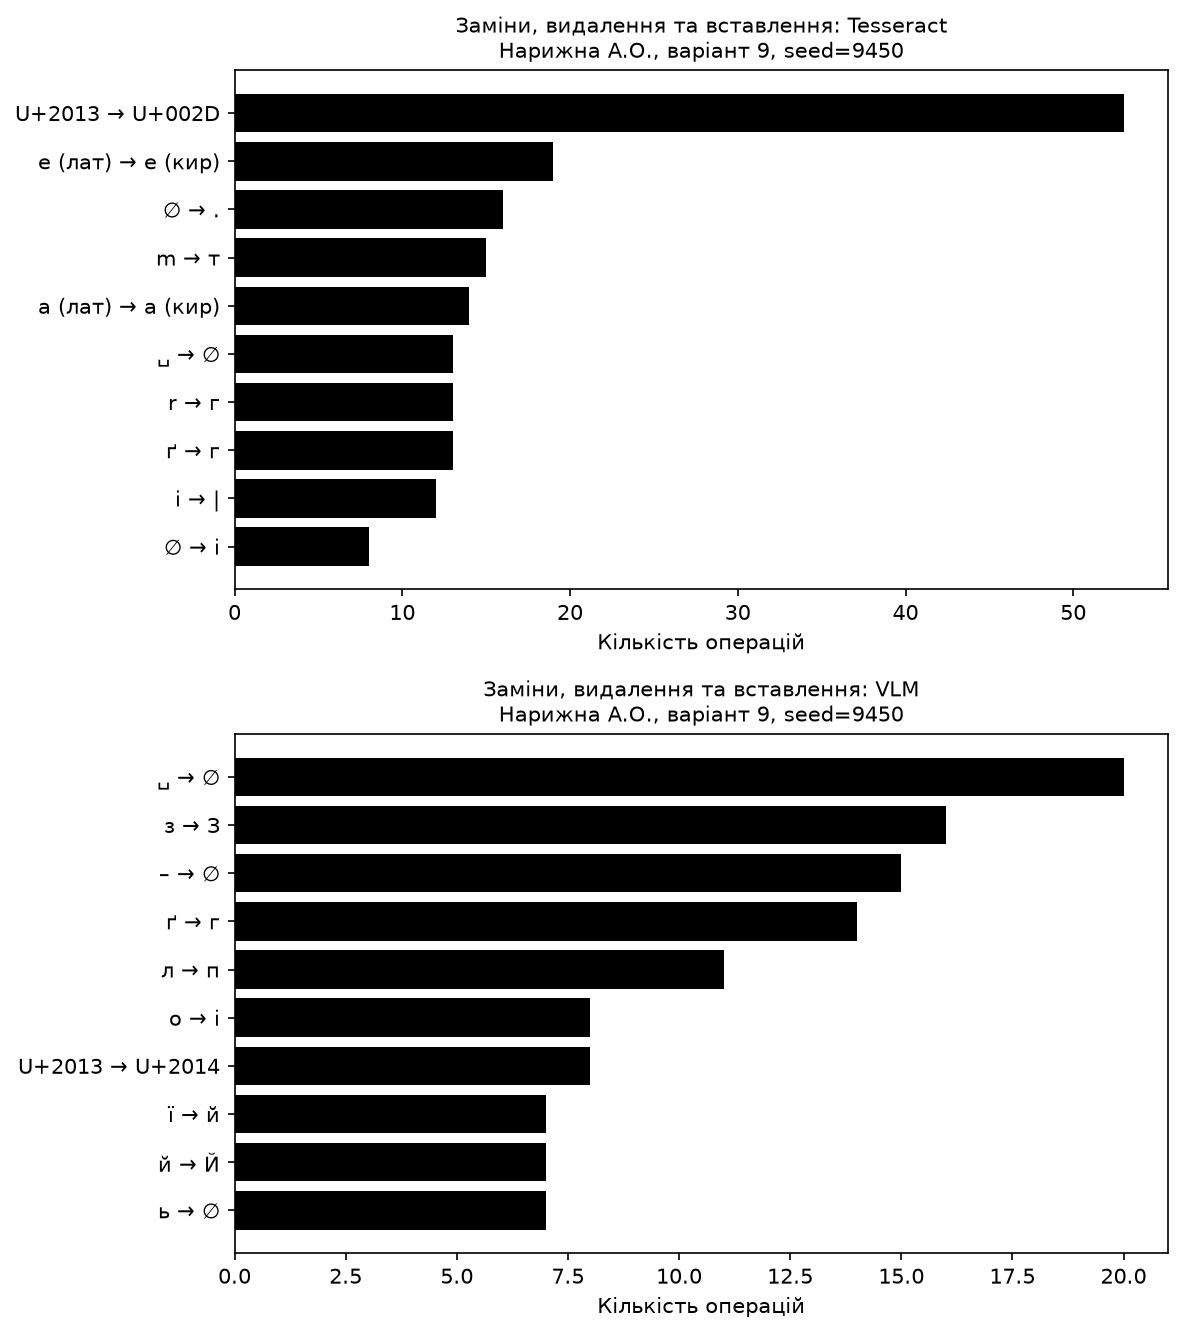

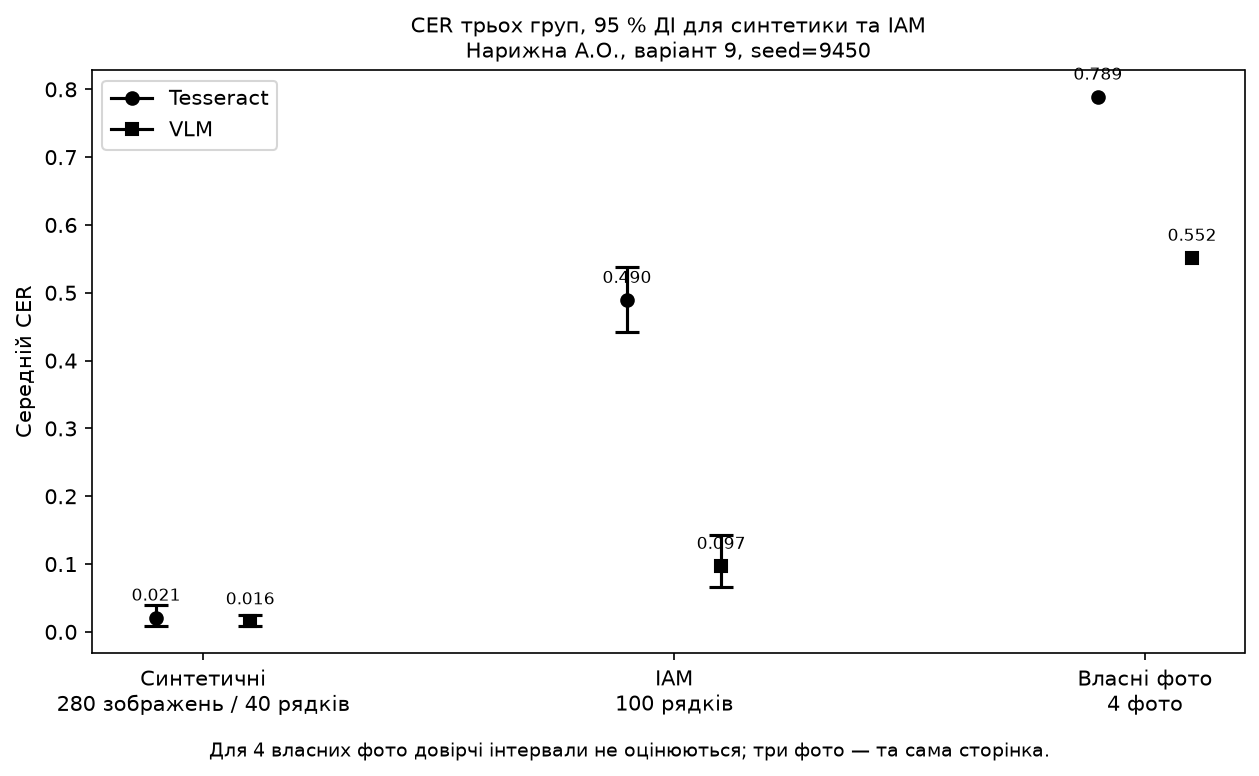

Спірмен: rho=-0.601050, p=6.88484e-29


In [1]:
from pathlib import Path
from collections import Counter
import re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rapidfuzz.distance import Levenshtein
from scipy.stats import spearmanr

STUDENT, VARIANT, SEED = "Нарижна А.О.", 9, 9450
rng_plot = np.random.default_rng(SEED)
res = pd.read_csv("results.csv", dtype={"id": str}, keep_default_na=False)
synthetic = res[(res["group"] == "synthetic") & (res["prep"] == "raw")]
Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"font.size": 10})

def stamp(ax, title):
    ax.set_title(f"{title}\n{STUDENT}, варіант {VARIANT}, seed={SEED}", fontsize=10)

def boot_ci(x, n_boot=2000, alpha=0.05):
    x = np.asarray(x, dtype=float)
    means = rng_plot.choice(x, size=(n_boot, len(x)), replace=True).mean(axis=1)
    return np.quantile(means, [alpha / 2, 1 - alpha / 2])

def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

# 1. Стійкість: 40 однакових рядків на кожній висоті, 95 % бутстреп-інтервали.
fig, ax = plt.subplots(figsize=(8, 4.8))
for engine, style in [("Tesseract", "-o"), ("VLM", "--s")]:
    groups = synthetic[synthetic.engine == engine].groupby("level")["cer"]
    means = groups.mean()
    ci = np.array([boot_ci(v) for _, v in groups])
    ax.plot(means.index, means.values, style, color="black", label=engine)
    ax.fill_between(means.index, ci[:, 0], ci[:, 1], color="black", alpha=0.12)
ax.axhline(0.10, ls=":", color="black", label="поріг CER = 10 %")
ax.invert_xaxis()
ax.set_xticks([40, 32, 24, 18, 14, 12, 10])
ax.set_xlabel("Висота тексту, px (праворуч — дрібніший текст)")
ax.set_ylabel("Середній CER, частка")
ax.legend()
stamp(ax, "Стійкість до зменшення тексту, 95 % ДІ")
save(fig, "fig1_robustness")

# 2. Розподіл CER на висоті 10 px.
LVL = 10
fig, ax = plt.subplots(figsize=(7, 4.6))
engines = ["Tesseract", "VLM"]
values = [synthetic[(synthetic.engine == e) & (synthetic.level == LVL)].cer.values
          for e in engines]
ax.boxplot(values, tick_labels=engines, showmeans=True, showfliers=False,
           meanprops={"marker": "^", "markerfacecolor": "black", "markeredgecolor": "black"},
           medianprops={"color": "black"})
for i, v in enumerate(values, 1):
    ax.scatter(i + rng_plot.uniform(-0.08, 0.08, len(v)), v, s=16,
               facecolors="none", edgecolors="black", alpha=0.6)
ax.set_ylabel("CER окремого рядка, частка")
stamp(ax, f"Розподіл CER за висоти {LVL} px, n = 40")
save(fig, "fig2_boxplot")

# 3. Впевненість і ризик-покриття: лише Tesseract, синтетичні дані.
g = synthetic[synthetic.engine == "Tesseract"].copy()
g["conf"] = pd.to_numeric(g["conf"])
rho, p_value = spearmanr(g.conf, g.cer)
fig, axes = plt.subplots(2, 1, figsize=(8, 8))
axes[0].scatter(g.conf, g.cer, s=16, facecolors="none", edgecolors="black", alpha=0.5)
axes[0].set_xlabel("Впевненість Tesseract")
axes[0].set_ylabel("CER, частка")
stamp(axes[0], f"Впевненість і CER, ρ = {rho:.3f}")
# Усі зразки з однаковою впевненістю приймаються разом.
risk = g.groupby("conf").agg(total=("cer", "sum"), n=("cer", "size")).sort_index(ascending=False)
coverage = risk.n.cumsum() / len(g)
mean_risk = risk.total.cumsum() / risk.n.cumsum()
axes[1].plot(coverage, mean_risk, color="black", marker=".")
axes[1].axhline(0.02, ls=":", color="black", label="CER = 2 %")
axes[1].set_xlabel("Частка прийнятих рядків")
axes[1].set_ylabel("Середній CER прийнятих рядків")
axes[1].legend()
stamp(axes[1], "Ризик-покриття Tesseract")
save(fig, "fig3_confidence")
print(f"Спірмен: rho={rho:.6f}, p={p_value:.6g}")

# 4. Якість і час: окремі панелі груп та явні позначення обладнання.
# Три збережені локальні проби VLM виключено з хмарної панелі обох інструментів.
time_data = res.copy()
local_trials = ((time_data["group"] == "synthetic") & (time_data.level == 32)
                & time_data.id.isin(["0", "1", "2"]))
time_data = time_data[~local_trials]
fig, axes = plt.subplots(3, 1, figsize=(8, 10))
for ax, group, title in zip(axes, ["synthetic", "iam", "own"],
                            ["Синтетика, 277 зразків", "IAM, 100 зразків", "Власні фото, 4 зразки"]):
    for engine, marker in [("Tesseract", "o"), ("VLM", "s")]:
        part = time_data[(time_data["group"] == group) & (time_data.engine == engine)]
        x, y = part.sec.mean(), part.cer.mean()
        device = "CPU" if engine == "Tesseract" or group == "own" else "Colab T4"
        ax.scatter(x, y, color="black", marker=marker, s=55,
                   label=f"{engine} ({device})")
    from matplotlib.ticker import NullLocator
    ax.set_xscale("log")
    times = [time_data[(time_data["group"] == group) & (time_data.engine == e)].sec.mean() for e in engines]
    ax.set_xticks(times, [f"{t:.2f}" for t in times])
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlabel("Середній час OCR, с (лог. шкала)")
    ax.set_ylabel("Середній CER")
    ax.legend(fontsize=8)
    stamp(ax, title)
fig.text(0.5, -0.025, "CPU та Colab T4 — різне обладнання; час не ізолює швидкість алгоритму.",
         ha="center", fontsize=9)
save(fig, "fig4_tradeoff")

# 5. Абляція з уже виконаного пункту 9.
abl = pd.read_csv("ablation_results.csv").groupby("step", sort=False).cer.mean()
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(abl.index[::-1], abl.values[::-1], color="black")
for y, v in enumerate(abl.values[::-1]):
    ax.text(v + 0.002, y, f"{v:.3f}", va="center", fontsize=9)
ax.set_xlim(0, max(0.1, abl.max() * 1.2))
ax.set_xlabel("Середній CER Tesseract")
stamp(ax, "Абляція попередньої обробки, висота = 10 px")
save(fig, "fig5_ablation")

# 6. Найчастіші операції редагування на синтетичних даних (CER < 0.5).
def normalize(s):
    s = unicodedata.normalize("NFC", str(s))
    for a in "\u2019\u02bc\u2018\u0060\u00b4":
        s = s.replace(a, "'")
    return re.sub(r"\s+", " ", s).strip()

def sym(c):
    return "␣" if c == " " else c

fig, axes = plt.subplots(2, 1, figsize=(8, 9))
for ax, engine in zip(axes, engines):
    counts = Counter()
    for r in synthetic[(synthetic.engine == engine) & (synthetic.cer < 0.5)].itertuples():
        gt, pred = normalize(r.gt), normalize(r.pred)
        for op in Levenshtein.editops(gt, pred):
            if op.tag == "replace":
                a, b = gt[op.src_pos], pred[op.dest_pos]
                label = f"{sym(a)} → {sym(b)}"
                aliases = str.maketrans("аеорсхуіАЕОРСХУІ", "aeopcxyiAEOPCXYI")
                if a != b and a.translate(aliases) == b.translate(aliases):
                    left = "лат" if "LATIN" in unicodedata.name(a, "") else "кир"
                    right = "лат" if "LATIN" in unicodedata.name(b, "") else "кир"
                    label = f"{a} ({left}) → {b} ({right})"
                elif a != b and a in "-–—−" and b in "-–—−":
                    label = f"U+{ord(a):04X} → U+{ord(b):04X}"
            elif op.tag == "delete":
                label = f"{sym(gt[op.src_pos])} → ∅"
            else:
                label = f"∅ → {sym(pred[op.dest_pos])}"
            counts[label] += 1
    top = counts.most_common(10)[::-1]
    ax.barh([x[0] for x in top], [x[1] for x in top], color="black")
    ax.set_xlabel("Кількість операцій")
    stamp(ax, f"Заміни, видалення та вставлення: {engine}")
save(fig, "fig6_confusions")

# 7. Три групи даних; синтетика — кластерний бутстреп за id рядка.
fig, ax = plt.subplots(figsize=(8.5, 5))
groups = ["synthetic", "iam", "own"]
for offset, engine, marker in [(-0.1, "Tesseract", "o"), (0.1, "VLM", "s")]:
    for i, group in enumerate(groups):
        part = res[(res.engine == engine) & (res["group"] == group)]
        mean = part.cer.mean()
        x = i + offset
        ax.plot(x, mean, marker=marker, color="black", label=engine if i == 0 else None)
        if group != "own":
            units = part.groupby("id").cer.mean() if group == "synthetic" else part.cer
            low, high = boot_ci(units)
            ax.vlines(x, low, high, color="black")
            ax.hlines([low, high], x-0.025, x+0.025, color="black")
        ax.text(x, mean + 0.025, f"{mean:.3f}", ha="center", fontsize=8)
ax.set_xticks(range(3), ["Синтетичні\n280 зображень / 40 рядків", "IAM\n100 рядків", "Власні фото\n4 фото"])
ax.set_ylabel("Середній CER")
ax.legend()
stamp(ax, "CER трьох груп, 95 % ДІ для синтетики та IAM")
fig.text(0.5, -0.02, "Для 4 власних фото довірчі інтервали не оцінюються; три фото — та сама сторінка.",
         ha="center", fontsize=9)
save(fig, "fig7_groups")


## Пункт 13 Аналіз результатів
Додатковий дослід 40 → 160 рядків збережено окремо: data/ci_extension160. Основний набір не змінено.


In [1]:
import re,unicodedata,json
from pathlib import Path
from collections import Counter
import numpy as np,pandas as pd
from rapidfuzz.distance import Levenshtein
from scipy.stats import spearmanr

rng=np.random.default_rng(9450)
res=pd.read_csv('results.csv',dtype={'id':str},keep_default_na=False)
syn=res[res.group=='synthetic'].copy()
def norm(s):
 s=unicodedata.normalize('NFC',str(s))
 for c in '\u2019\u02bc\u2018\u0060\u00b4':s=s.replace(c,"'")
 return re.sub(r'\s+',' ',s).strip()
def cer(g,p):
 g,p=norm(g),norm(p);return Levenshtein.distance(g,p)/max(1,len(g))
def ci(x):
 x=np.asarray(x,dtype=float);return np.quantile(rng.choice(x,(2000,len(x)),replace=True).mean(axis=1),[.025,.975]).tolist()
curves=[]
for (eng,lvl),g in syn.groupby(['engine','level']):
 lo,hi=ci(g.cer);curves.append({'engine':eng,'level':int(lvl),'mean':g.cer.mean(),'median':g.cer.median(),'low':lo,'high':hi,'width':hi-lo})
pivot=syn.pivot(index=['id','level'],columns='engine',values='cer')
diff=pivot.Tesseract-pivot.VLM;by=diff.groupby('level').mean();level=int(by.abs().idxmax());pairs=diff.xs(level,level='level')
box=[]
for e,g in syn[syn.level==10].groupby('engine'):
 box.append({'engine':e,'mean':g.cer.mean(),'median':g.cer.median(),'exact_one':int(g.cer.eq(1).sum()),'at_least_one':int(g.cer.ge(1).sum()),'max':g.cer.max()})
t=syn[syn.engine=='Tesseract'].copy();t['conf']=pd.to_numeric(t.conf)
rho,p=spearmanr(t.conf,t.cer)
a=t.groupby('conf').agg(total=('cer','sum'),n=('cer','size')).sort_index(ascending=False)
a['coverage']=a.n.cumsum()/len(t);a['risk']=a.total.cumsum()/a.n.cumsum()
best=a[a.risk<=.02].iloc[-1];threshold=float(a[a.risk<=.02].index[-1])
counts={}
for e,g in syn[syn.cer<.5].groupby('engine'):
 c=Counter()
 for r in g.itertuples():
  gt,pred=norm(r.gt),norm(r.pred)
  for op in Levenshtein.editops(gt,pred):
   if op.tag=='replace':pair=(gt[op.src_pos],pred[op.dest_pos])
   elif op.tag=='delete':pair=(gt[op.src_pos],'∅')
   else:pair=('∅',pred[op.dest_pos])
   c[pair]+=1
 counts[e]=[{'from':a,'to':b,'count':n} for (a,b),n in c.most_common(5)]
# Три правила, без використання еталону для виправлення відповіді.
translation=str.maketrans('аеорсхуіАЕОРСХУІ','aeopcxyiAEOPCXYI')
def mixed(s):
 return re.sub(r'\b[^\W\d_]+\b',lambda m:m.group().translate(translation) if re.search('[A-Za-z]',m.group()) else m.group(),s)
def dash(s):return re.sub(r'(?<=\s)[-—](?=\s)','–',s)
def dot(s):return s.rstrip()[:-1] if s.rstrip().endswith('.') else s
post=[]
for e,g in syn.groupby('engine'):
 for name,fn in [('Кириличні гомогліфи у словах із латиницею',mixed),('Тире між пробілами',dash),('Видалення кінцевої крапки',dot)]:
  changed=[cer(r.gt,fn(str(r.pred))) for r in g.itertuples()]
  post.append({'engine':e,'rule':name,'before':g.cer.mean(),'after':float(np.mean(changed))})
ratio=res[res.engine=='VLM'].copy()
ratio['len_ratio']=[len(norm(p))/max(1,len(norm(g))) for g,p in zip(ratio['gt'],ratio['pred'])]
ratio.to_csv('vlm_length_results.csv',index=False)
length=ratio[ratio.group=='synthetic'].groupby('level').agg(mean=('len_ratio','mean'),median=('len_ratio','median'),min=('len_ratio','min'),max=('len_ratio','max'))
length.to_csv('vlm_length_summary.csv')
post=pd.DataFrame(post);post.to_csv('postprocessing_comparison.csv',index=False)
means=res.groupby(['engine','group']).cer.mean()
ratios=[]
for e in ['Tesseract','VLM']:ratios.append({'engine':e,'own_to_synthetic':means[e,'own']/means[e,'synthetic'],'own_to_iam':means[e,'own']/means[e,'iam']})
own=res[res.group=='own'][['engine','id','cer','wer','sec']].to_dict('records')
bad=syn[(syn.level==10)&(syn.cer>=1)][['engine','id','level','gt','pred','cer']].to_dict('records')
report={'curves':curves,'pair_level':level,'pair_mean':pairs.mean(),'pair_ci':ci(pairs),'box':box,'rho':float(rho),'rho_p':float(p),'threshold':threshold,'coverage':float(best.coverage),'risk':float(best.risk),'top_errors':counts,'postprocessing':post.to_dict('records'),'ratios':ratios,'own':own,'failures':bad,'length_cases':ratio.nlargest(4,'len_ratio')[['group','id','level','gt','pred','cer','len_ratio']].to_dict('records')}
Path('analysis13.json').write_text(json.dumps(report,ensure_ascii=False,indent=2),encoding='utf-8')
print(json.dumps(report,ensure_ascii=False,indent=2))


Статистику, три правила постобробки та відношення довжин збережено в окремі JSON і CSV.


In [1]:
import pandas as pd
import numpy as np
extension = pd.read_csv('data/ci_extension160/extension_results.csv', keep_default_na=False)
assert extension.groupby('engine').size().to_dict() == {'Tesseract': 160, 'VLM': 160}
rng = np.random.default_rng(9450)
for engine, group in extension.groupby('engine'):
    for n, part in [(40, group[group.trial_id.str.startswith('base_')]), (160, group)]:
        x = part.cer.to_numpy()
        interval = np.quantile(rng.choice(x, (2000, len(x)), replace=True).mean(axis=1), [.025, .975])
        print(engine, n, 'CER:', x.mean(), '95% CI:', interval, 'width:', np.diff(interval)[0])


[
  {
    "engine": "Tesseract",
    "n": 40,
    "mean": 0.05271094859357106,
    "low": 0.034869181901070925,
    "high": 0.0771263808147735,
    "width": 0.04225719891370258
  },
  {
    "engine": "Tesseract",
    "n": 160,
    "mean": 0.045500143482940195,
    "low": 0.03952177010735495,
    "high": 0.05289517301593917,
    "width": 0.013373402908584221
  },
  {
    "engine": "VLM",
    "n": 40,
    "mean": 0.0440278365884549,
    "low": 0.012078629446077653,
    "high": 0.10125822044745408,
    "width": 0.08917959100137643
  },
  {
    "engine": "VLM",
    "n": 160,
    "mean": 0.021104672237990778,
    "low": 0.011911007405887217,
    "high": 0.035676245689282224,
    "width": 0.023765238283395006
  }
]

## 7 Інтерпретація графіків

### 7.1 Крива стійкості
На рисунку 6 вісь X показує висоту тексту в пікселях, вісь Y — середній CER по 40 рядках. Орієнтиром є CER = 10 %. За висоти 40–14 px результати відносно стабільні; при 12–10 px помилка зростає. На 10 px Tesseract має CER 5,27 %, VLM — 4,40 %; на 24 px — 1,27 % і 0,91 %. Жодне середнє не перевищує 10 %, тому точку перетину порога в дослідженому діапазоні не знайдено. Криві середніх не перетинаються: VLM має нижче середнє на кожній висоті. Це не доводить значущості кожної різниці: смуги перекриваються.

Аномалія VLM на 10 px — рядок id=15 із CER 103,13 % через вигадане продовження. Саме такі рідкісні відповіді розширюють довірчу смугу. Практичне рішення — по можливості використовувати більшу висоту тексту та перевіряти довгі відповіді VLM. Для перевірки механізму деградації слід порівняти ті самі рядки на 10 і 24 px; сама зміна середнього не відокремлює втрату штрихів від мовного доповнення.

### 7.2 Діаграма розмаху
На рисунку 7 показано CER кожного з 40 рядків на висоті 10 px. Лінія в коробці — медіана, трикутник — середнє, точки — окремі спостереження. У Tesseract середнє 5,27 % вище за медіану 3,25 %, у VLM середнє 4,40 % за медіани 0 %. Більшість відповідей VLM точні, але окремий провал істотно збільшує середнє. Найгірший CER Tesseract — 40,00 % на рядку з латинською цитатою; найгірший VLM — 103,13 % через вставлення тексту.

Середнє не описує типовий рядок VLM, тому для вибору інструмента потрібні також медіана та частка провалів. У VLM один із 40 рядків має CER ≥ 1, у Tesseract таких рядків немає. Висновок обмежений одним рівнем і 40 зразками. Додаткова перевірка — відкрити крайні випадки та порівняти операції редагування, а не вважати всі відхилення випадковим шумом.

### 7.3 Впевненість і ризик покриття
На рисунку 8 кожна точка ліворуч — одне з 280 синтетичних зображень Tesseract: впевненість по X та CER по Y. Спірмен ρ = −0,601 означає помітний від’ємний зв’язок, але не гарантує правильності відповіді. Праворуч показано середній CER прийнятої частки рядків; орієнтир — 2 %. При прийнятті всіх рядків CER становить 2,12 %. Поріг впевненості 0,635 залишає 276 із 280 зображень (98,57 %) із середнім CER 1,87 %.

Крива не зобов’язана бути монотонною: додавання нової порції рядків може знизити середню помилку. Однакові впевненості приймаються разом. Поріг підібрано й оцінено на тих самих даних, тому його не можна вважати перевіреною гарантією на нових фото. Для практичного застосування потрібна окрема контрольна вибірка. Для VLM ρ і поріг впевненості не визначаються, бо conf відсутній; вигадувати його із довжини відповіді некоректно.

### 7.4 Компроміс часу та CER
На рисунку 9 кожна точка відображає середній час OCR і CER інструмента в межах групи. Вісь часу логарифмічна. Синтетична панель використовує ті самі 277 зображень обох інструментів, виключивши три локальні проби VLM. Tesseract має 0,118 с і CER 2,14 %, VLM у Colab — 2,254 с і 1,58 %. Для IAM значення становлять 0,204 с і 48,96 % проти 1,948 с і 9,74 %. Для власних фото локально — 2,167 с і 78,93 % проти 413,902 с і 55,18 %.

У кожній панелі один інструмент швидший, інший має менший CER; домінування одночасно за обома критеріями немає. Це компроміс саме виконаних запусків: Tesseract і хмарна VLM працювали на різному обладнанні. Власні фото VLM також мають інший контекст (8192) та значно більшу площу зображення. Для коректного висновку про швидкість самих алгоритмів слід повторити запуск на одному обладнанні. Високий CER власного рукопису означає, що швидкість сама по собі не робить результат придатним до автоматичного використання.

### 7.5 Абляційний експеримент
На рисунку 10 вісь X показує середній CER Tesseract, вісь Y — послідовні конфігурації обробки на тих самих 40 рядках висотою 10 px. База без обробки — 5,27 %. Збільшення ×2 дає 1,34 %, додавання медіанного фільтра — 1,60 %, додавання Оцу — 3,23 %, адаптивна бінаризація замість Оцу — 2,49 %. Найбільше зниження порівняно з базою дає лише збільшення: 3,93 відсоткового пункту.

Фільтр і бінаризація в цьому наборі погіршують результат відносно одного збільшення, хоча всі середні кращі за базу. Ймовірне пояснення — деформація тонких штрихів після згладжування та порогової обробки; це пояснення не доведене самою діаграмою. Практичний вибір для цієї синтетичної вибірки — збільшення без додаткових кроків. Перевірити пояснення можна візуальним зіставленням рядків, у яких CER зріс після фільтра або Оцу. На чотирьох власних фото такий ефект ще не вимірювався, тому переносити його автоматично не можна.

### 7.6 Операції редагування
На рисунку 11 показано частоту замін, вставлень і видалень у синтетичних відповідях з CER < 0,5. Для Tesseract переважає заміна довгого тире на дефіс — 53 операції; для VLM — видалення пробілу, 20 операцій. Схожі латинські та кириличні літери позначено окремо, оскільки вони мають різні Unicode-коди. Відбір частково правильних відповідей дозволяє бачити систематичні помилки, але виключає повний провал VLM із CER 1,03125.

Частота операцій не дорівнює числу незалежних рядків: той самий текст представлено на семи висотах. На цій діаграмі немає довірчих інтервалів, тому її слід використовувати для формулювання правил, а не для доведення їхньої універсальності. У питанні 8 нижче наведено виміряний ефект трьох правил. Додаткова перевірка має проводитися на даних, які не використовувалися для вибору правил.

### 7.7 Порівняння трьох груп
На рисунку 12 вісь Y — середній CER, вісь X — група даних. Для Tesseract значення становлять 2,12 % на синтетиці, 48,96 % на IAM і 78,93 % на власних фото; для VLM — 1,57 %, 9,74 % та 55,18 %. База — синтетичні рядки. На реальному рукописі помилка обох інструментів значно вища; найбільший розрив спостерігається на власних фотографіях.

Інтервали синтетики обчислено за кластерами початкових рядків, щоб не трактувати сім висот як незалежні тексти. Для IAM використано 100 рядків. Для власних фото є лише чотири спостереження, три з яких відтворюють ту саму сторінку; довірчі інтервали не наведено. Групи відрізняються мовою, одиницею оцінювання та типом почерку, тому графік не доводить причинного впливу лише одного чинника. Для власних фото потрібен ручний контроль; перевірити узагальнюваність можна на більшій кількості незалежних сторінок.

## 8 Індивідуальні питання підрозділу 7.3

### 1 Поріг CER та перетин кривих
На всіх семи висотах середній CER нижчий за 10 % в обох інструментів. Найбільші середні на 10 px: 5,27 % і 4,40 %. Тому рівень першого перевищення не визначено в межах проведеного експерименту; вигадувати його за межами діапазону не можна. Криві середніх не перетинаються, але це не доводить статистично надійного ранжування на кожній висоті.

### 2 Довірчі інтервали та розмір вибірки
На плато 24 px ширина 95 % інтервалу становить приблизно 2,90 відсоткового пункту для Tesseract і 1,00 для VLM; на 10 px — 4,23 та 8,82 відповідно. Найбільша ширина відповідає 10 px. За наближенням ширини інтервалу як 1/√n для її зменшення вдвічі потрібно вчетверо більше рядків: 160 замість 40, тобто додати 120 незалежних рядків.

Для фактичної перевірки до 40 початкових рядків додано 120 інших рядків твору Івана Франка «Перехресні стежки» (SEED = 9450), збережено Arial і висоту 10 px. Tesseract виконано локально з ukr, OEM 1, PSM 7; 120 нових відповідей qwen2.5vl:3b отримано в Colab на GPU T4 з тим самим запитом і temperature = 0. Початкові 40 відповідей повторно не розпізнавалися. Для кожної моделі є 160 результатів; додатковий дослід збережено окремо від основних 768 відповідей. У повторному розрахунку з 2000 бутстреп-перевибірок отримано:

| Інструмент | n | CER, % | 95 % ДІ, % | Ширина, в.п. |
|---|---|---|---|---|
| Tesseract | 40 | 5.27 | 3.49–7.71 | 4.23 |
| Tesseract | 160 | 4.55 | 3.95–5.29 | 1.34 |
| VLM | 40 | 4.40 | 1.21–10.13 | 8.92 |
| VLM | 160 | 2.11 | 1.19–3.57 | 2.38 |

Ширина інтервалу зменшилася з 4,23 до 1,34 відсоткового пункту для Tesseract і з 8,92 до 2,38 для VLM. Невелика відмінність початкового інтервалу VLM від рисунка 6 спричинена іншою позицією генератора під час бутстрепу. Звуження більше ніж удвічі; це не точна перевірка закону 1/√n, оскільки додані тексти змінили розподіл помилок і частку рідкісних провалів.

### 3 Парна різниця CER
Найбільша абсолютна різниця середніх спостерігається на 12 px: Tesseract 2,33 %, VLM 1,19 %. Парна різниця Tesseract − VLM становить 1,14 відсоткового пункту. Її 95 % бутстреп-інтервал по 40 парах приблизно [−0,18; 3,08] відсоткового пункту і містить нуль. На цих даних недостатньо підстав стверджувати надійну перевагу за цим рівнем лише з різниці середніх.

### 4 Медіана середнє та провали
Для 10 px Tesseract: середнє 5,27 %, медіана 3,25 %; VLM: середнє 4,40 %, медіана 0 %. Частка CER рівно 1 — 0 % для обох інструментів. Якщо повний провал визначати як CER ≥ 1, VLM має 1/40 = 2,5 %, Tesseract — 0 %. Відкрито зображення id=15, висота 10 px: на ньому є лише початковий рядок, а VLM додала відсутнє продовження «відкритого простору, він відчував непередбачуваність та непокій». Причина — вставлення вигаданого тексту, а не лише втрата символів. Найгірший Tesseract має CER 40 % на рядку з латинською цитатою, що узгоджується з невідповідністю змішаного тексту режиму ukr.

### 5 Впевненість та поріг прийняття
Спірмен Tesseract на синтетичних зображеннях: ρ = −0,601. Поріг conf ≥ 0,635 приймає 276/280 зображень, або 98,57 %, із середнім CER 1,87 %. Решта 4/280 потребують перевірки. Це результат підбору на цій самій вибірці, а не гарантія для нових даних. Для VLM коефіцієнт та поріг не визначаються через відсутність conf, як зазначено в підрозділі 4.9 методички.

### 6 Домінування та обробка 10000 сторінок
На рисунку 9 немає домінованої конфігурації в межах кожної групи: Tesseract швидший, VLM точніша. За середнім часом чотирьох власних сторінок Tesseract вимагав би близько 6,02 години на 10000 сторінок, локальна VLM — приблизно 1149,73 години. Це груба екстраполяція лише чотирьох фото, а не перевірений прогноз промислового навантаження. За жорсткої нічної часової межі Tesseract можна розглядати для першого проходу з подальшою перевіркою, однак CER 78,93 % на цьому рукописі не дозволяє рекомендувати його для автономного отримання правильного тексту. Жоден із двох варіантів на власних фото не забезпечив низького CER; потрібні інші умови обробки або ручна перевірка.

### 7 Внесок кроків попередньої обробки
Найбільший приріст дала операція збільшення ×2: CER 5,27 % → 1,34 %. Додавання медіанного фільтра підвищило помилку до 1,60 %, Оцу — до 3,23 %. Гіпотеза передбачала зниження щонайменше на 5 відсоткових пунктів для повного ланцюжка; фактичне зниження становить 2,04 відсоткового пункту. Ці значення не досягають прогнозованого ефекту. Остаточне оформлення оцінки всіх гіпотез належить до пункту 16. Механізм втрати тонких штрихів залишається поясненням, яке потребує візуальної перевірки.

### 8 Типові помилки та вимірювання постобробки
П’ять найчастіших операцій Tesseract: тире «–» → дефіс «-» (53); латинська e → кирилична е (19); вставлення крапки (16); латинська m → кирилична т (15); латинська a → кирилична а (14). Для VLM: видалення пробілу (20), з → З (16), видалення «–» (15), ґ → г (14), л → п (11).

Окремо перевірено три правила на всіх 280 синтетичних відповідях кожної моделі. Правило 1 — заміна кириличних гомогліфів на латинські всередині слова, яке містить латиницю: Tesseract 2,1218 % → 2,1218 %, VLM 1,5691 % → 1,6340 %. Правило 2 — відновлення «–» замість дефіса чи довгого тире між пробілами: Tesseract 2,1218 % → 1,9184 %, VLM 1,5691 % → 1,5335 %. Правило 3 — видалення кінцевої крапки: Tesseract 2,1218 % → 2,0479 %, VLM 1,5691 % → 1,6066 %.

Кожне правило оцінено окремо, без використання еталону для виправлення відповіді. Правило тире дало невелике зниження для обох моделей; правила гомогліфів і кінцевої крапки не є універсально корисними. Наприклад, видалення справжньої крапки створює нову помилку. Правила обрано на тих самих даних, тому їхній ефект є описовим; первинні відповіді та метрики пункту 11 не змінено.

### 9 Власні фотографії та умови зйомки
Середній CER власних фото відносно синтетики вищий у 37,20 раза для Tesseract і 35,17 раза для VLM; відносно IAM — у 1,61 і 5,66 раза відповідно. Це порівняння груп різного змісту, а не ізольований ефект лише зйомки.

Серед трьох фото української сторінки Tesseract найгірше розпізнав IMG_1404 зі зйомкою під кутом: CER 82,07 %. Для VLM найгірше IMG_1402 із тінню: 94,66 %. Найкращий результат обох інструментів — IMG_1403 із відносно рівним освітленням: 77,93 % і 48,28 %. Для кожної умови є лише один кадр, тому причинне пояснення впливом тіні або перспективи не підтверджене незалежними повтореннями.

### 10 Особливість варіанта Галюцинації VLM
Для кожної відповіді VLM обчислено len_ratio = довжина нормалізованої відповіді / довжина нормалізованого еталону. Значення понад 1 свідчить про більшу кількість символів, менше 1 — про меншу; жодне з них саме по собі не доводить або не виключає галюцинацію.

| Висота, px | Середнє len_ratio | Медіана | Мінімум | Максимум |
|---|---|---|---|---|
| 10 | 1.0181 | 1.0000 | 0.8889 | 2.0156 |
| 12 | 0.9956 | 1.0000 | 0.9365 | 1.0182 |
| 14 | 0.9963 | 1.0000 | 0.9667 | 1.0000 |
| 18 | 0.9988 | 1.0000 | 0.9667 | 1.0182 |
| 24 | 0.9975 | 1.0000 | 0.9667 | 1.0000 |
| 32 | 0.9966 | 1.0000 | 0.9500 | 1.0159 |
| 40 | 0.9963 | 1.0000 | 0.9500 | 1.0156 |


У синтетичному рядку id=15 на висоті 10 px len_ratio = 2,015625 та CER = 1,03125. Порівняння з відкритим зображенням підтверджує відсутність вигаданого продовження на самому рядку. Середнє len_ratio для цього рівня лише 1,018: воно приховує одиничний великий провал. Інший підтверджений приклад — IAM id=34: еталон «vision .», відповідь «$\frac{25}{10}$», len_ratio = 1,875 та CER = 1,875. На зображенні видно рукописне слово, а не дріб, тому математичний запис є помилковою інтерпретацією. Для контролю потрібні одночасно len_ratio, CER і перегляд зображення; поріг тільки за довжиною може пропустити заміну тексту зі збереженням довжини.


## Пункт 14 Аналіз п’яти найгірших зразків
Вибрано п’ять відповідей з найбільшим CER серед основних 768 результатів. При однаковому CER використано WER, далі — початковий порядок у results.csv. Додатковий дослід пункту 13 не включено. Для кожного зразка наведено зображення, еталон, результат і категорію причини помилки.


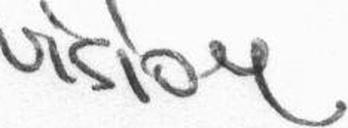

iam, id=34, VLM, CER=1.875000, WER=1.000000
Еталон: vision .
Результат: $\frac{25}{10}$
Категорія: Галюцинація
На зображенні видно рукописне слово «vision», а відповідь містить математичний дріб, якого немає в оригіналі. Це помилкова інтерпретація візуального вмісту VLM; відношення довжин становить 1,875. CER перевищує 1 через кількість операцій редагування відносно короткого еталону.


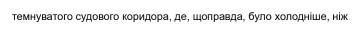

synthetic, id=15, VLM, CER=1.031250, WER=1.000000
Еталон: темнуватого судового коридора, де, щоправда, було холодніше, ніж
Результат: Темнуватого судового коридора, де, щоправда, було холодніше, ніж відкритого простору, він відчував непередбачуваність та непокій.
Категорія: Галюцинація
На зображенні є один друкований рядок. VLM відтворила його з відмінністю регістру й додала відсутнє продовження «відкритого простору, він відчував непередбачуваність та непокій». Вставлення вигаданого продовження збільшило CER понад 1; відношення довжин дорівнює 2,015625.


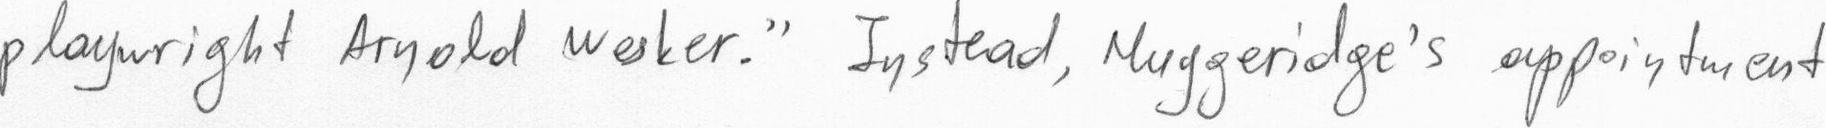

iam, id=17, Tesseract, CER=1.000000, WER=1.000000
Еталон: playwright Arnold Wesker . " Instead , Muggeridge's appointment
Результат: [порожній текст]
Категорія: Сегментація або відхилення результату розпізнавання
Рядок рукопису присутній і візуально читається, але Tesseract у режимі PSM 7 повернув порожню відповідь, confidence = 0. Зв’язне написання та нестандартні форми літер могли спричинити невдалу сегментацію або відхилення розпізнаного рядка. За підсумковою порожньою відповіддю точно розрізнити ці внутрішні причини неможливо. Повний пропуск еталону дає CER = WER = 1.


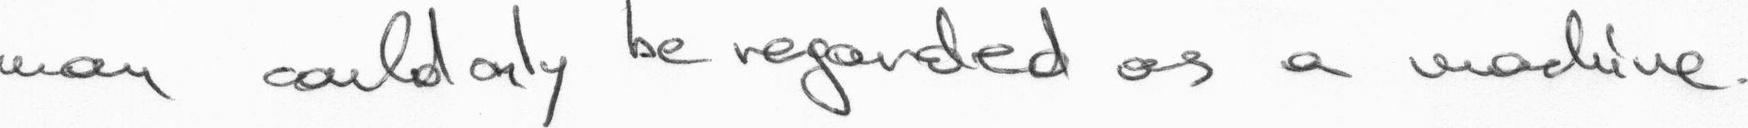

iam, id=23, Tesseract, CER=1.000000, WER=1.000000
Еталон: man could only be regarded as a machine .
Результат: [порожній текст]
Категорія: Сегментація або відхилення результату розпізнавання
На зображенні видно слова рукописного речення з довгими з’єднаннями між літерами. Tesseract повернув порожній текст і confidence = 0, тобто пропущено всі символи та слова еталону. Імовірна причина — невдала сегментація зв’язного рукопису або неприйняття результату моделлю; встановити конкретний внутрішній етап лише з CSV неможливо.


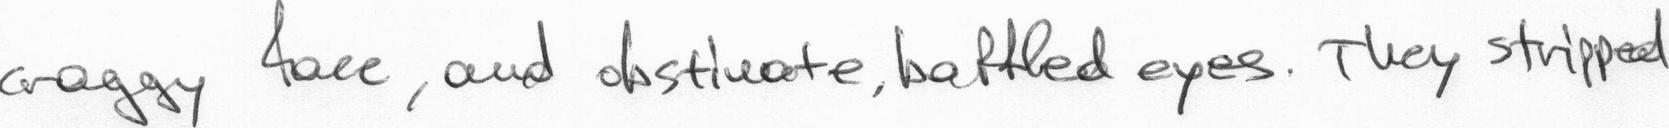

iam, id=30, Tesseract, CER=1.000000, WER=1.000000
Еталон: craggy face , and obstinate , baffled eyes . They stripped
Результат: [порожній текст]
Категорія: Сегментація або відхилення результату розпізнавання
Зображення містить цілий рукописний рядок із нерівними інтервалами та з’єднаними літерами. Tesseract не повернув тексту, confidence = 0. Це повний пропуск рядка, а не окремі заміни символів. Невдала сегментація чи відхилення розпізнавання є можливими причинами; конкретна внутрішня причина не підтверджена журналом моделі.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image

res = pd.read_csv("results.csv", dtype={"id": str}, keep_default_na=False)
worst5 = res.sort_values(["cer", "wer"], ascending=False, kind="stable").head(5)
analysis = pd.read_csv("worst5_analysis.csv", dtype={"id": str}, keep_default_na=False)
keys = ["group", "id", "level", "engine", "prep"]
assert worst5[keys].reset_index(drop=True).equals(analysis[keys].reset_index(drop=True))
for r in analysis.itertuples(index=False):
    print(r.group, r.id, r.engine, "CER =", r.cer, "WER =", r.wer)
    display(Image(filename=str(Path(r.path))))
    print("Еталон:", r.gt)
    print("Результат:", r.pred if r.pred else "[порожній текст]")
    print("Категорія:", r.category)
    print("Причина:", r.analysis, "\n")


## Пункт 15 Збереження власних результатів у JSON
Файл own_recognition.json містить усі 8 результатів: чотири фото для двох інструментів. Обидва інструменти на власних фото працювали локально. Для VLM confidence = null. Версію сервера Ollama під час запуску не зафіксовано, тому її не підмінено версією Python-бібліотеки. Для варіанта 9 вилучення полів рахунків не передбачено.

Поточна версія сервера за наданою відповіддю /api/version — 0.40.15. Це перевірка після розпізнавання; історичну версію не підтверджено.


In [1]:
from pathlib import Path
import json
import hashlib
import pandas as pd

res = pd.read_csv('recognition_results.csv', dtype={'id': str}, keep_default_na=False)
metadata = json.loads(Path('recognition_metadata.json').read_text(encoding='utf-8'))
own = res[(res['group'] == 'own') & (res['prep'] == 'raw')].copy()
assert own.groupby('engine').size().to_dict() == {'Tesseract': 4, 'VLM': 4}
assert not own.duplicated(['id', 'engine', 'model', 'prep']).any()
records = []
for r in own.itertuples(index=False):
    image = Path('data/my_photos') / (r.id + '.png')
    vlm = r.engine == 'VLM'
    records.append({
        'id': r.id,
        'image': image.as_posix(),
        'image_sha256': hashlib.sha256(image.read_bytes()).hexdigest(),
        'engine': r.engine,
        'version': r.model if vlm else metadata['tesseract'],
        'ollama_python_version': metadata['ollama_python'] if vlm else None,
        'ollama_server_version': None,
        'ollama_server_current': metadata.get('ollama_server_current') if vlm else None,
        'execution': 'local CPU',
        'preprocessing': r.prep,
        'parameters': ({'temperature': 0, 'num_gpu': 0, 'num_ctx': 8192,
                        'prompt': metadata['prompt']} if vlm else
                       {'lang': r.lang, 'oem': 1, 'psm': int(r.psm)}),
        'confidence': None if vlm or r.conf == '' else float(r.conf),
        'seconds': float(r.sec),
        'text': r.pred,
    })
output = Path('own_recognition.json')
output.write_text(json.dumps(records, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
saved = json.loads(output.read_text(encoding='utf-8'))
assert len(saved) == 8
for source, restored in zip(own.itertuples(index=False), saved):
    assert source.pred == restored['text']
    assert float(source.sec) == restored['seconds']
print('Збережено own_recognition.json: 4 фото × 2 інструменти = 8 записів.')
print('Версія сервера Ollama під час розпізнавання не зафіксована: null.')


Збережено own_recognition.json: 4 фото × 2 інструменти = 8 записів.
Версія сервера Ollama під час розпізнавання не зафіксована: null.


## Пункт 16 Перевірка гіпотез і висновки


In [1]:
import pandas as pd

results = pd.read_csv('results.csv', dtype={'id': str}, keep_default_na=False)
tess = results[(results.engine == 'Tesseract') & (results.prep == 'raw')]
cer32 = tess[(tess.group == 'synthetic') & (tess.level == 32)].cer.mean()
cer10 = tess[(tess.group == 'synthetic') & (tess.level == 10)].cer.mean()
ablation = pd.read_csv('ablation_summary.csv')
cer_otsu = ablation.loc[ablation.step == '+ бінаризація Оцу', 'CER_mean'].iloc[0]
own_ukr = tess[(tess.group == 'own') & tess.id.isin(['IMG_1402', 'IMG_1403', 'IMG_1404'])].cer.mean()
evaluation = pd.DataFrame([
    {'hypothesis': 1, 'criterion': 'CER32 <= 0.10 and CER10 > 0.10',
     'actual': f'CER32={cer32:.8f}; CER10={cer10:.8f}',
     'status': 'підтверджено' if cer32 <= .10 and cer10 > .10 else 'спростовано'},
    {'hypothesis': 2, 'criterion': 'CER_raw - CER_otsu >= 0.05',
     'actual': f'difference={cer10 - cer_otsu:.8f}',
     'status': 'підтверджено' if cer10 - cer_otsu >= .05 else 'спростовано'},
    {'hypothesis': 3, 'criterion': 'CER_own_ukr >= 2 * CER32',
     'actual': f'CER_own_ukr={own_ukr:.8f}; ratio={own_ukr / cer32:.8f}',
     'status': 'підтверджено' if own_ukr >= 2 * cer32 else 'спростовано'},
])
evaluation.to_csv('hypotheses_evaluation.csv', index=False)
print(evaluation.to_string(index=False))


Гіпотеза 1: спростовано; CER32 = 0.01684633, CER10 = 0.05271095.
Гіпотеза 2: спростовано; зниження CER = 0.02039218.
Гіпотеза 3: підтверджено; CER трьох українських фото = 0.79942529, відношення = 47.45396206.


## 11 Перевірка гіпотез

Перевірено три гіпотези, зафіксовані комітом ac12a6b від 08.11.2026 о 14:50:12 (+02:00). Використано початкові критерії та ті самі групи даних, які визначено до експериментів.

Гіпотеза 1 — спростовано. Прогноз для Tesseract передбачав CER ≤ 10 % за висоти 32 px та CER > 10 % за висоти 10 px. Фактично отримано 1,68 % та 5,27 % відповідно. Перша нерівність виконується, друга — ні, тому сукупний критерій не виконано. Зменшення висоти погіршило якість, але вплив виявився слабшим за прогнозований: чистий друкований текст залишався достатньо читабельним.

Гіпотеза 2 — спростовано. Очікувалося, що збільшення ×2, медіанний фільтр та Оцу знизять CER щонайменше на 5 відсоткових пунктів. На 40 синтетичних рядках висотою 10 px CER змінився з 5,27 % до 3,23 %, тобто лише на 2,04 відсоткового пункту. Найкращим було одне збільшення — CER 1,34 %. Фільтрація й бінаризація після нього погіршили результат; можливе пояснення — спотворення тонких штрихів, однак самі метрики не доводять цей механізм.

Гіпотеза 3 — підтверджено за заданим числовим критерієм. Середній CER Tesseract на трьох українських фотографіях IMG_1402–IMG_1404 дорівнює 79,94 %, на синтетичних рядках 32 px — 1,68 %. Помилка власних фото вища у 47,45 раза, що перевищує прогнозовані два рази. Англомовне фото IMG_1405 у цю перевірку не включено. Результат узгоджується зі складністю рукопису та умов зйомки, але не відокремлює вплив почерку, тіні й перспективи.

## 12 Висновки

Побудовано конвеєр OCR і порівняно Tesseract та qwen2.5vl:3b на 280 синтетичних зображеннях, 100 рядках IAM і чотирьох власних фото. Основний набір містить 768 результатів. Якість оцінено за CER і WER зі збереженням регістру та пунктуації; результати власних фото експортовано у JSON із метаданими.

На синтетичних даних без обробки середній CER становить 2,12 % для Tesseract і 1,57 % для VLM, середній WER — 6,86 % та 5,63 %. Для швидкої обробки дрібного друкованого тексту за досліджених умов обрано Tesseract з ukr, OEM 1, PSM 7 і збільшенням ×2: у відповідному абляційному досліді на 10 px CER знизився до 1,34 %. Цей вибір підтверджено лише для зазначених синтетичних рядків.

Для англійського рукопису IAM доцільніше обрати qwen2.5vl:3b з temperature = 0: CER становить 9,74 % проти 48,96 % у Tesseract, WER — 33,97 % проти 89,28 %. Синтетичні та відкриті дані VLM переважно оброблено у Colab на GPU T4; чотири власні фото — локально на CPU. Порівняння часу відображає різне обладнання та не доводить різницю швидкості самих алгоритмів.

На власних фото VLM має нижчий середній CER — 55,18 % проти 78,93 % у Tesseract, проте обидва результати потребують ручного виправлення. Для цих фото VLM використовувала num_gpu = 0 та num_ctx = 8192; середній час становив 413,90 с проти 2,17 с у Tesseract. Для локальної роботи з цим рукописом автоматичне отримання точного тексту не забезпечене.

Основні обмеження — 40 початкових синтетичних рядків, один відкритий набір, чотири власні фото, з яких три відтворюють одну сторінку, та ризик галюцинацій VLM. Відношення довжин допомагає знаходити підозрілі відповіді, але потребує зіставлення із зображенням і CER. Поріг впевненості Tesseract 0,635 дав CER 1,87 % при покритті 98,57 % лише на вибірці, де його підібрано. Дві початкові гіпотези спростовано, одну підтверджено; універсальної переваги одного інструмента для всіх умов не встановлено.

## 13 Декларація використання ШІ

| Інструмент | Для чого використано | Що студент перевірив або змінив самостійно |
|---|---|---|
| ChatGPT / Codex | Допомога з підготовкою й виправленням коду, розрахунками, аналізом результатів. Оформлення тексту, таблиць та ілюстрацій звіту. | Надала власні фотографії, текстові файли й вимоги до оформлення; обрала модель qwen2.5vl:3b та запускала комірки. |
| qwen2.5vl:3b через Ollama | Розпізнавання тексту із зображень: синтетичні та відкриті дані переважно в Colab, власні фото локально. | Запускала розпізнавання в Colab і локально; надала повідомлення про помилки та відповідь сервера щодо поточної версії. |
